# European Greeks Deep Dive: 1-Month Call and Call with Terminal Knock-Out
## Where Fournié Localization Helps and Where It Does Not

---

### Overview
1. **The 1-month call ($T = 1/12$).** The standard Malliavin weights grow as the maturity shrinks: $\pi^\Delta \propto T^{-1/2}$ and $\pi^\Gamma \propto T^{-1}$ in units of $Z = W_T/\sqrt{T}$. The call payoff is unbounded, so multiplying it by these weights gives a large per-path variance. Fournié localization uses the weight only near the strike and the pathwise derivative elsewhere. The variance reductions below are measured on simulated paths, not assumed.

2. **The call with terminal knock-out ($H = 105.25$, $T = 1$).** The payoff $(S_T - K)^+ \mathbf{1}_{S_T \le H}$ is checked at maturity only and is non-zero only on $[100, 105.25]$, where it is at most $5.25$. Standard Malliavin already has a small variance there, and localization does not help Delta or Gamma. We also show that the choice of the combined cutoff matters: $\psi_K + \psi_H$ is biased with the Gaussian cutoff, while $1 - (1-\psi_K)(1-\psi_H)$ is not.

Contents:
- **Part 1: the 1-month call ($T = 1/12$)**
  1. Spot distribution and the width of the diffusion ($S_0\sigma\sqrt{T} \approx 5.77$).
  2. Payoff, cutoff and residue in the Fournié decomposition, and the 5 cutoff families.
  3. Greeks with standard errors: analytical vs. standard Malliavin vs. Fournié.
  4. Variance as a function of the bandwidth $\delta$, a dedicated Vega analysis, and per-Greek (decoupled) bandwidths.
  5. Delta across spot $S_0 \in [80, 120]$ and convergence in $N$.
- **Part 2: the call with terminal knock-out ($H = 105.25$)**
  6. The two ways to combine the cutoffs, their bias, and their variance compared with standard Malliavin.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

from products import (
    example_european_call_1M,
    example_european_call_ATM,
    example_european_call_terminal_knockout,
)
from Methods.Analytic.europeans import (
    greeks_european_call,
    d1,
    d2,
    greeks_european_barrier_up_and_out_call,
    price_barrier_up_and_out_call,
    delta_barrier_up_and_out_call,
    gamma_barrier_up_and_out_call,
    vega_barrier_up_and_out_call,
)
from Methods import payoffs
from Methods.sampling import generate_paths, simulate_terminal_spot
from Methods.Malliavin import (
    fournier_bandwidths,
    get_cutoff,
    malliavin_fournier_greeks_european_barrier_up_and_out_call,
    malliavin_fournier_samples_european_call,
    malliavin_fournier_samples_european_call_terminal_knockout,
    malliavin_samples_european,
)

# Configure publication-quality visual styling
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "lines.linewidth": 2.2,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})
sns.set_theme(style="whitegrid", palette="deep")

pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 16)
pd.set_option("display.width", 1000)

print("Environment configured successfully.")
print("1-Month European Call Parameters:")
for k, v in example_european_call_1M.items():
    print(f"  {k:8s}: {v}")
print("\nCall with Terminal Knock-Out Parameters:")
for k, v in example_european_call_terminal_knockout.items():
    print(f"  {k:8s}: {v}")


Environment configured successfully.
1-Month European Call Parameters:
  S0      : 100
  K       : 100
  T       : 0.08333333333333333
  r       : 0.05
  q       : 0.02
  sigma   : 0.2
  name    : Call European 1M

Call with Terminal Knock-Out Parameters:
  S0      : 100
  K       : 100
  T       : 1
  r       : 0.05
  q       : 0.02
  H       : 105.25
  sigma   : 0.2
  name    : Call with terminal knock-out


---
## 1. Product Specifications & Terminal Spot Distribution: $T = 1.0$ vs. $T = 1/12$

Under the Black-Scholes risk-neutral measure $\mathbb{Q}$, the terminal asset price is lognormally distributed:
$$\ln S_T \sim \mathcal{N}\left( \ln S_0 + \left(r - q - \frac{1}{2}\sigma^2\right)T, \; \sigma^2 T \right)$$

The characteristic diffusion width of the spot distribution scales as:
$$\sigma_{\text{spot}} \approx S_0 \sigma \sqrt{T}$$
- **1-Year Horizon ($T = 1.0$):** $\sigma_{\text{spot}} \approx 100 \times 0.20 \times 1.0 = \$20.00$.
- **1-Month Horizon ($T = 1/12$):** $\sigma_{\text{spot}} \approx 100 \times 0.20 \times \sqrt{1/12} \approx \$5.77$.

Because the diffusion width is compressed by $\sqrt{12} \approx 3.46\times$, terminal paths are tightly packed around $K = 100$. Any smoothing window $\delta$ that was appropriate for 1 year ($\delta = 8.0$) is now wider than the entire active trading band!

<>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:24: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:27: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:27: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:37: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:24: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:24: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences wil

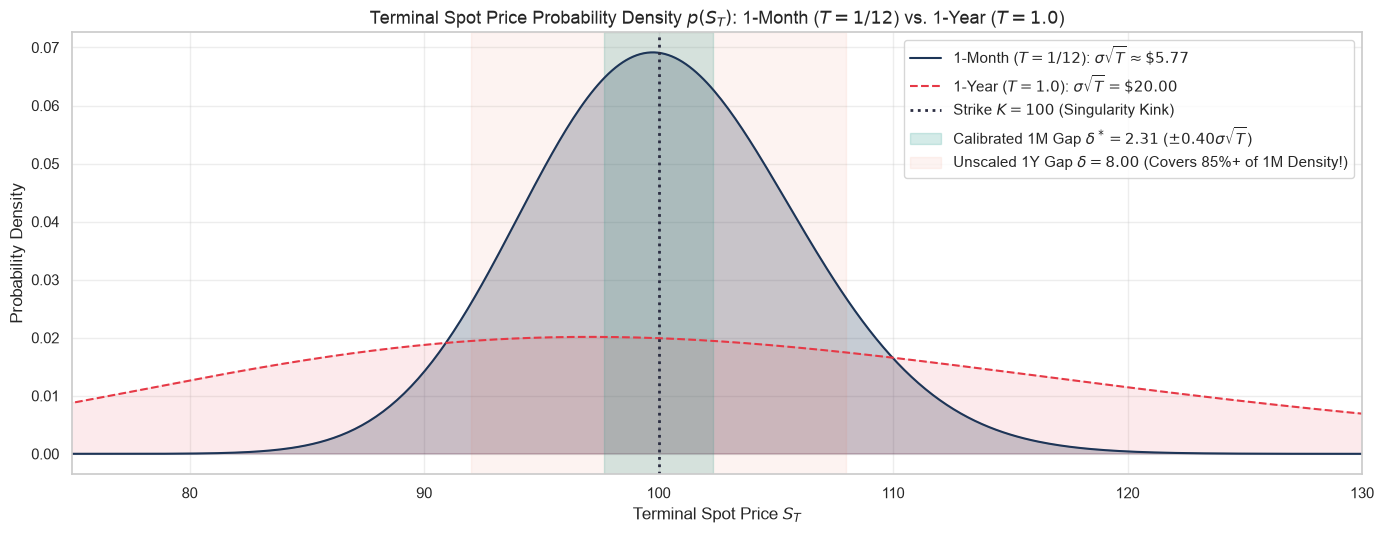

In [2]:
p_1M = example_european_call_1M
p_1Y = example_european_call_ATM

S0, K, r, q, sigma = p_1M["S0"], p_1M["K"], p_1M["r"], p_1M["q"], p_1M["sigma"]
T_1M, T_1Y = p_1M["T"], p_1Y["T"]

# Analytical lognormal densities
spots = np.linspace(60, 150, 600)

def lognormal_pdf(s, S0, T, r, q, sigma):
    drift = np.log(S0) + (r - q - 0.5 * sigma**2) * T
    vol = sigma * np.sqrt(T)
    return (1.0 / (s * vol * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((np.log(s) - drift) / vol)**2)

pdf_1M = lognormal_pdf(spots, S0, T_1M, r, q, sigma)
pdf_1Y = lognormal_pdf(spots, S0, T_1Y, r, q, sigma)

# Standard deviations
std_1M = S0 * sigma * np.sqrt(T_1M)
std_1Y = S0 * sigma * np.sqrt(T_1Y)

fig, ax = plt.subplots(figsize=(14, 5.5))

ax.plot(spots, pdf_1M, color="#1d3557", label=f"1-Month ($T = 1/12$): $\sigma\\sqrt{{T}} \\approx \${std_1M:.2f}$")
ax.fill_between(spots, pdf_1M, alpha=0.25, color="#1d3557")

ax.plot(spots, pdf_1Y, color="#e63946", linestyle="--", label=f"1-Year ($T = 1.0$): $\sigma\\sqrt{{T}} = \${std_1Y:.2f}$")
ax.fill_between(spots, pdf_1Y, alpha=0.10, color="#e63946")

ax.axvline(K, color="#2b2d42", linestyle=":", linewidth=2.0, label=f"Strike $K = {K:.0f}$ (Singularity Kink)")

# Overlay bandwidths
delta_1Y = 8.0
delta_1M = fournier_bandwidths(p_1M, coupled=True)["delta"]

ax.axvspan(K - delta_1M, K + delta_1M, color="#2a9d8f", alpha=0.20,
           label=f"Calibrated 1M Gap $\\delta^* = {delta_1M:.2f}$ ($\pm 0.40\\sigma\\sqrt{{T}}$)")
ax.axvspan(K - delta_1Y, K + delta_1Y, color="#e76f51", alpha=0.08,
           label=f"Unscaled 1Y Gap $\\delta = {delta_1Y:.2f}$ (Covers 85%+ of 1M Density!)")

ax.set_title("Terminal Spot Price Probability Density $p(S_T)$: 1-Month ($T = 1/12$) vs. 1-Year ($T = 1.0$)", fontsize=13)
ax.set_xlabel("Terminal Spot Price $S_T$")
ax.set_ylabel("Probability Density")
ax.set_xlim(75, 130)
ax.legend(frameon=True, facecolor="white", loc="upper right")
plt.tight_layout()
plt.show()


---
## 2. Fournié Payoff Decomposition Anatomy: Payoff, Cutoff, and Residue Functions

The mathematical heart of Fournié localization is the partition of unity.
Given the Call payoff $g(S_T) = (S_T - K)^+$ and a smooth cutoff $\psi(S_T)$:

$$g(S_T) = \underbrace{g_{\text{loc}}(S_T)}_{\text{Localized Singular Core}} + \underbrace{g_{\text{res}}(S_T)}_{\text{Smooth Exterior Residue}}$$

where:
1. **The Payoff:** $g(S_T) = \max(S_T - K, 0)$. Has a continuous kink (non-differentiable singularity) at $S_T = K$.
2. **The Cutoff Function:** $\psi(S_T) = \exp\left(-\frac{1}{2}\left(\frac{S_T - K}{\delta}\right)^2\right)$. Satisfies $\psi(K) = 1$ and decay to $0$.
3. **The Localized Singular Part:** $g_{\text{loc}}(S_T) = g(S_T) \psi(S_T)$. Concentrates entirely around the kink. Handled by **Malliavin Integration by Parts (IBP)**.
4. **The Smooth Residue Part:** $g_{\text{res}}(S_T) = g(S_T) (1 - \psi(S_T))$. Tends to $0$ near $K$ and smoothly recovers the payoff far away. Handled by **Pathwise Differentiation (IPA)**.
5. **The Boundary Derivative:** $-\psi'(S_T) = \frac{S_T - K}{\delta^2} \psi(S_T)$. Adjusts for the boundary interaction via product rule differentiation.
6. **The Payoff Derivative Decomposition:**
   $$g'(S_T) = \mathbf{1}_{S_T > K} = \underbrace{\mathbf{1}_{S_T > K} \psi(S_T)}_{\text{Localized Step}} + \underbrace{\mathbf{1}_{S_T > K} (1 - \psi(S_T))}_{\text{Residue Step}}$$

Below, we visualize this complete mathematical anatomy across 4 coordinated panels!

<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:49: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:49: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:66: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:79: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:49: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences wil

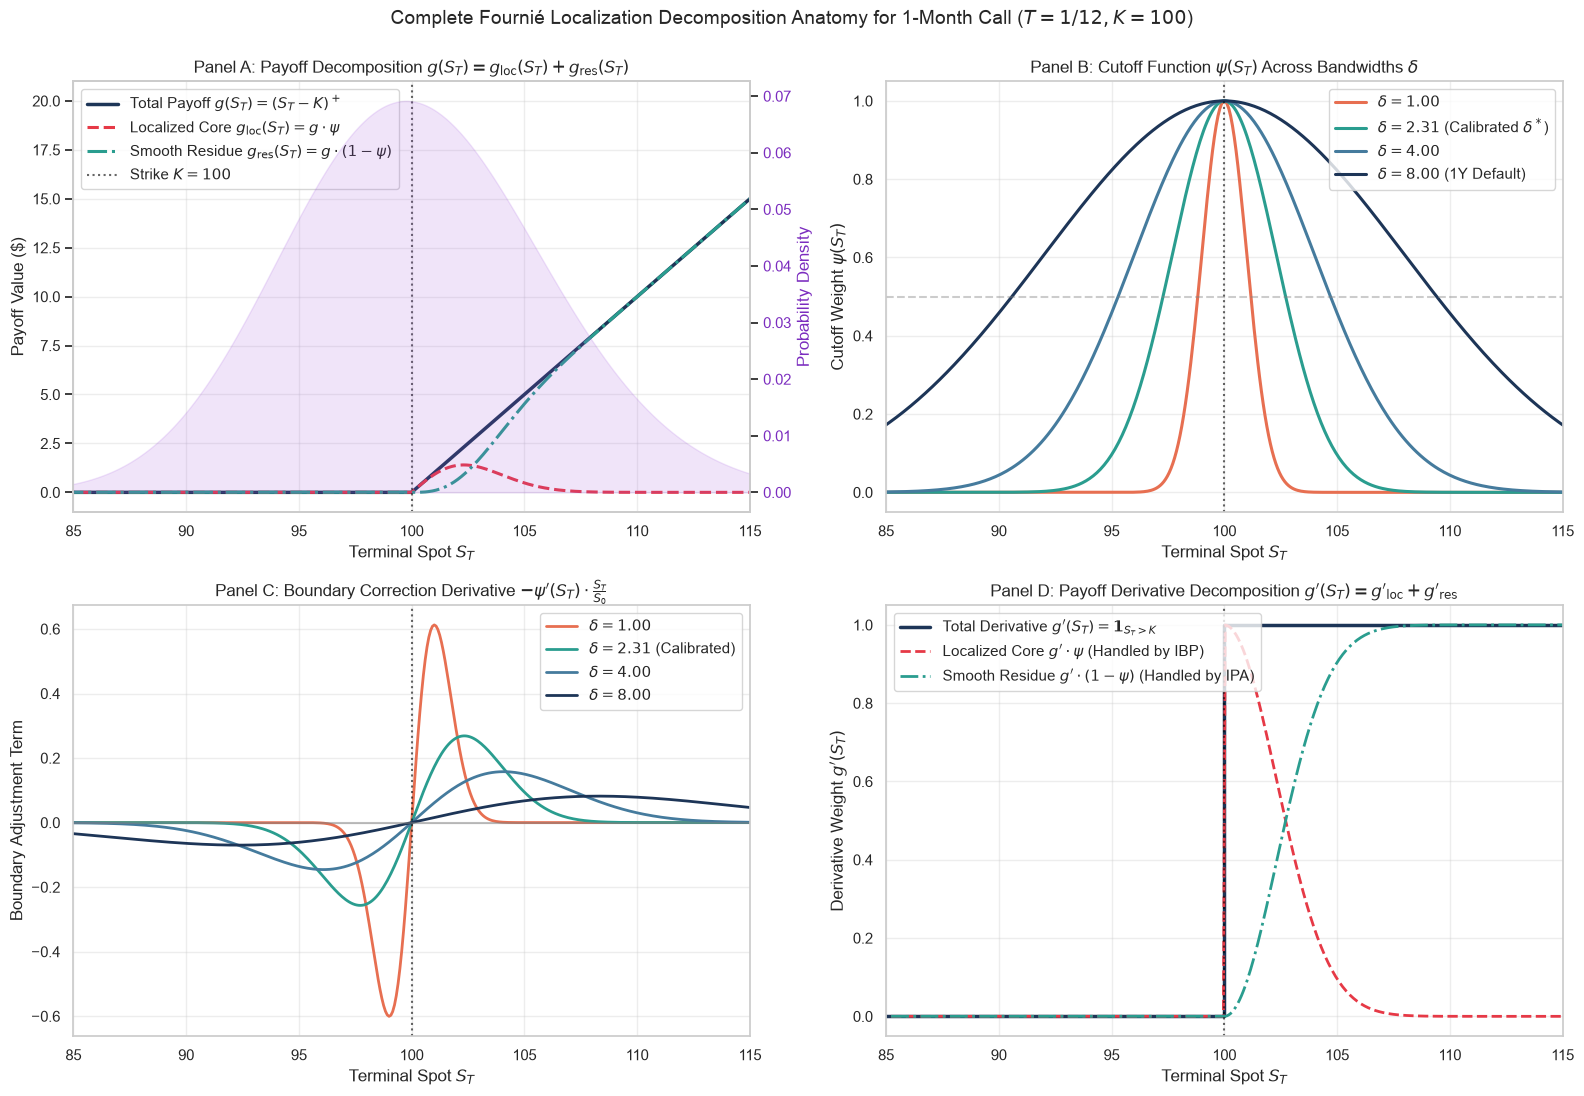

In [3]:
s_grid = np.linspace(80, 120, 500)
delta_calib = fournier_bandwidths(p_1M, coupled=True)["delta"]  # 0.40 * S0 * sigma * sqrt(T) ~ 2.3094

# Payoff and derivatives
payoff_vals = np.maximum(s_grid - K, 0.0)
payoff_deriv = (s_grid > K).astype(float)

# Cutoff and derivatives (Gaussian)
psi_vals, psi_prime_vals = get_cutoff(s_grid, K, bandwidth=delta_calib, cutoff_type="gaussian")

# Decompositions
g_loc = payoff_vals * psi_vals
g_res = payoff_vals * (1.0 - psi_vals)

g_prime_loc = payoff_deriv * psi_vals
g_prime_res = payoff_deriv * (1.0 - psi_vals)

# Create 4-panel comprehensive visual figure
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel A: Payoff Decomposition
ax_a = axes[0, 0]
ax_a.plot(s_grid, payoff_vals, label="Total Payoff $g(S_T) = (S_T - K)^+$", color="#1d3557", linewidth=2.5)
ax_a.plot(s_grid, g_loc, label=r"Localized Core $g_{\mathrm{loc}}(S_T) = g \cdot \psi$", color="#e63946", linestyle="--", linewidth=2.2)
ax_a.plot(s_grid, g_res, label=r"Smooth Residue $g_{\mathrm{res}}(S_T) = g \cdot (1 - \psi)$", color="#2a9d8f", linestyle="-.", linewidth=2.2)
ax_a.axvline(K, color="black", linestyle=":", alpha=0.6, label=f"Strike $K = {K}$")

# Add twin axis for spot density overlay
ax_a_twin = ax_a.twinx()
pdf_grid = lognormal_pdf(s_grid, S0, T_1M, r, q, sigma)
ax_a_twin.fill_between(s_grid, pdf_grid, color="#9d4edd", alpha=0.15, label="Spot Density $p(S_T)$ ($T = 1/12$)")
ax_a_twin.set_ylabel("Probability Density", color="#7b2cbf")
ax_a_twin.tick_params(axis="y", labelcolor="#7b2cbf")
ax_a_twin.grid(False)

ax_a.set_title("Panel A: Payoff Decomposition $g(S_T) = g_{\mathrm{loc}}(S_T) + g_{\mathrm{res}}(S_T)$", fontsize=12)
ax_a.set_xlabel("Terminal Spot $S_T$")
ax_a.set_ylabel("Payoff Value ($)")
ax_a.legend(loc="upper left", frameon=True)
ax_a.set_xlim(85, 115)

# Panel B: Smoothing Function psi(S_T) across Bandwidths delta
ax_b = axes[0, 1]
delta_sweep = [1.0, delta_calib, 4.0, 8.0]
palette_delta = ["#e76f51", "#2a9d8f", "#457b9d", "#1d3557"]

for d_val, c in zip(delta_sweep, palette_delta):
    psi_d, _ = get_cutoff(s_grid, K, bandwidth=d_val, cutoff_type="gaussian")
    lbl = f"$\delta = {d_val:.2f}$" + (" (Calibrated $\delta^*$)" if abs(d_val - delta_calib) < 1e-3 else "")
    lbl += " (1Y Default)" if abs(d_val - 8.0) < 1e-3 else ""
    ax_b.plot(s_grid, psi_d, label=lbl, color=c, linewidth=2.2)

ax_b.axvline(K, color="black", linestyle=":", alpha=0.6)
ax_b.axhline(0.5, color="gray", linestyle="--", alpha=0.4)
ax_b.set_title(r"Panel B: Cutoff Function $\psi(S_T)$ Across Bandwidths $\delta$", fontsize=12)
ax_b.set_xlabel("Terminal Spot $S_T$")
ax_b.set_ylabel(r"Cutoff Weight $\psi(S_T)$")
ax_b.legend(loc="upper right", frameon=True)
ax_b.set_xlim(85, 115)

# Panel C: Boundary Derivative Correction -psi'(S_T) * S_T / S0
ax_c = axes[1, 0]
for d_val, c in zip(delta_sweep, palette_delta):
    _, psi_prime_d = get_cutoff(s_grid, K, bandwidth=d_val, cutoff_type="gaussian")
    boundary_adj = -psi_prime_d * (s_grid / S0)
    lbl = f"$\delta = {d_val:.2f}$" + (" (Calibrated)" if abs(d_val - delta_calib) < 1e-3 else "")
    ax_c.plot(s_grid, boundary_adj, label=lbl, color=c, linewidth=2.0)

ax_c.axvline(K, color="black", linestyle=":", alpha=0.6)
ax_c.axhline(0.0, color="gray", linestyle="-", alpha=0.5)
ax_c.set_title(r"Panel C: Boundary Correction Derivative $-\psi'(S_T) \cdot \frac{S_T}{S_0}$", fontsize=12)
ax_c.set_xlabel("Terminal Spot $S_T$")
ax_c.set_ylabel("Boundary Adjustment Term")
ax_c.legend(loc="upper right", frameon=True)
ax_c.set_xlim(85, 115)

# Panel D: Payoff Derivative Decomposition g'(S_T) = 1_{S_T > K}
ax_d = axes[1, 1]
ax_d.step(s_grid, payoff_deriv, label="Total Derivative $g'(S_T) = \mathbf{1}_{S_T > K}$", color="#1d3557", where="mid", linewidth=2.5)
ax_d.plot(s_grid, g_prime_loc, label=r"Localized Core $g' \cdot \psi$ (Handled by IBP)", color="#e63946", linestyle="--", linewidth=2.0)
ax_d.plot(s_grid, g_prime_res, label=r"Smooth Residue $g' \cdot (1 - \psi)$ (Handled by IPA)", color="#2a9d8f", linestyle="-.", linewidth=2.0)
ax_d.axvline(K, color="black", linestyle=":", alpha=0.6)

ax_d.set_title(r"Panel D: Payoff Derivative Decomposition $g'(S_T) = g'_{\mathrm{loc}} + g'_{\mathrm{res}}$", fontsize=12)
ax_d.set_xlabel("Terminal Spot $S_T$")
ax_d.set_ylabel(r"Derivative Weight $g'(S_T)$")
ax_d.legend(loc="upper left", frameon=True)
ax_d.set_xlim(85, 115)

plt.suptitle("Complete Fournié Localization Decomposition Anatomy for 1-Month Call ($T = 1/12, K = 100$)", fontsize=14, y=0.995)
plt.tight_layout()
plt.show()


---
### 2.2 Comparison of the 5 Smoothing Cutoff Families

How does the mathematical morphology of the cutoff function $\psi(u)$ affect the estimator?
We compare:
1. **Gaussian ($C^\infty$, Non-compact):** $\psi(u) = \exp(-0.5 u^2)$. Peak gradient $\max |\psi'| = 0.606/\delta$.
2. **Cubic Hermite ($C^1$, Compact):** $\psi(u) = 1 - 3u^2 + 2u^3$ for $u \le 1$. Peak gradient $1.500/\delta$.
3. **Cosine ($C^1$, Compact):** $\psi(u) = \frac{1}{2}(1 + \cos(\pi u))$ for $u \le 1$. Peak gradient $1.571/\delta$.
4. **Quintic ($C^2$, Compact):** $\psi(u) = 1 - 10u^3 + 15u^4 - 6u^5$ for $u \le 1$. Peak gradient $1.875/\delta$.
5. **Cauchy ($C^\infty$, Non-compact):** $\psi(u) = \frac{1}{1 + u^2}$. Peak gradient $0.649/\delta$.

**Key Principle:** The Gaussian function features the **smallest peak gradient**, producing the gentlest boundary corrections and minimal boundary variance!

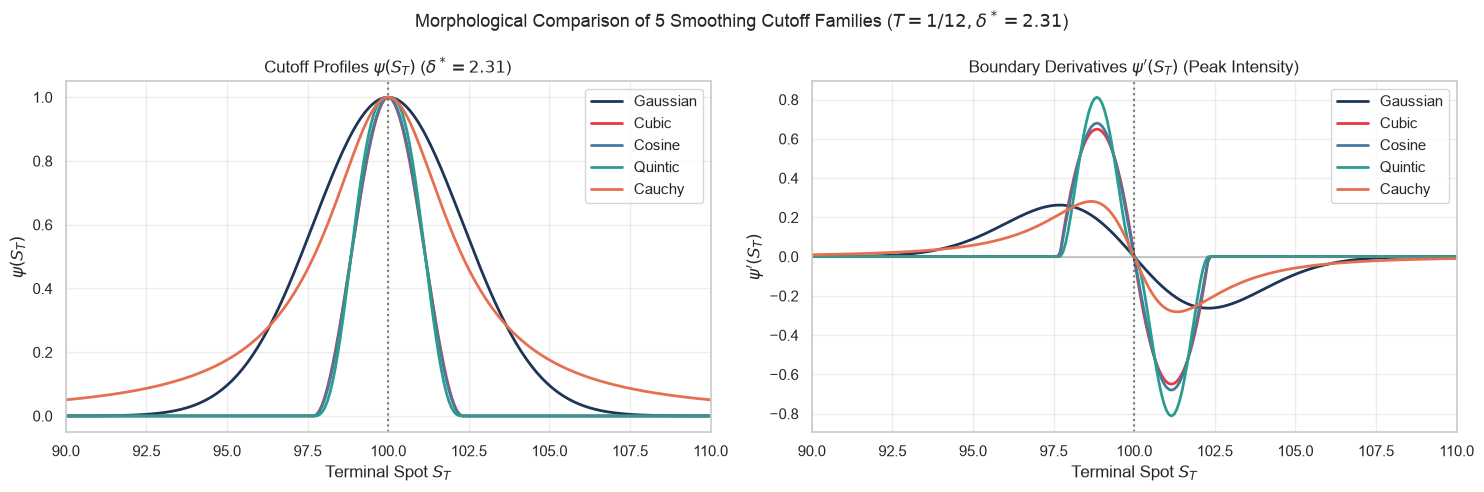

In [4]:
cutoff_types = ["gaussian", "cubic", "cosine", "quintic", "cauchy"]
colors_map = {
    "gaussian": "#1d3557",
    "cubic": "#e63946",
    "cosine": "#457b9d",
    "quintic": "#2a9d8f",
    "cauchy": "#e76f51",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

for ctype in cutoff_types:
    psi_c, psi_prime_c = get_cutoff(s_grid, K, bandwidth=delta_calib, cutoff_type=ctype)
    ax1.plot(s_grid, psi_c, label=ctype.capitalize(), color=colors_map[ctype], linewidth=2.0)
    ax2.plot(s_grid, psi_prime_c, label=ctype.capitalize(), color=colors_map[ctype], linewidth=2.0)

ax1.axvline(K, color="black", linestyle=":", alpha=0.5)
ax1.set_title(f"Cutoff Profiles $\\psi(S_T)$ ($\\delta^* = {delta_calib:.2f}$)")
ax1.set_xlabel("Terminal Spot $S_T$")
ax1.set_ylabel("$\\psi(S_T)$")
ax1.legend(frameon=True)
ax1.set_xlim(90, 110)

ax2.axvline(K, color="black", linestyle=":", alpha=0.5)
ax2.axhline(0.0, color="gray", linestyle="-", alpha=0.4)
ax2.set_title(f"Boundary Derivatives $\\psi'(S_T)$ (Peak Intensity)")
ax2.set_xlabel("Terminal Spot $S_T$")
ax2.set_ylabel("$\\psi'(S_T)$")
ax2.legend(frameon=True)
ax2.set_xlim(90, 110)

plt.suptitle(f"Morphological Comparison of 5 Smoothing Cutoff Families ($T = 1/12, \\delta^* = {delta_calib:.2f}$)", fontsize=13)
plt.tight_layout()
plt.show()


---
### 2.3 Visualizing Estimator Integrands Along Simulated Paths: Standard vs. Fournié

Why does Standard Malliavin suffer from high variance on short maturities?
Let us inspect the actual sample-by-sample values of the Delta estimator across simulated terminal spots $S_T$:
- **Standard Malliavin Sample:**
  $$Y_{\text{std}} = e^{-rT} g(S_T) \pi^\Delta = e^{-rT} (S_T - K)^+ \frac{W_T}{S_0 \sigma T}$$
- **Fournié Localized Sample:**
  $$Y_{\text{loc}} = e^{-rT} \left[ g(S_T)\left(\psi \pi^\Delta - \psi' \frac{S_T}{S_0}\right) + \mathbf{1}_{S_T > K}(1 - \psi)\frac{S_T}{S_0} \right]$$

Below, we scatter 5,000 Monte Carlo sample realisations against their respective terminal spot $S_T$!

<>:25: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:27: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:25: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:27: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/z3/4jhkb20n36z663jvlvmzxhj00000gn/T/ipykernel_37310/578799407.py:25: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  ax2.set_title("Fournié Localized Delta Integrand Samples ($\delta^* = 2.31$)", fontsize=12)
/var/folders/z3/4jhkb20n36z663jvlvmzxhj00000gn/T/ipykernel_37

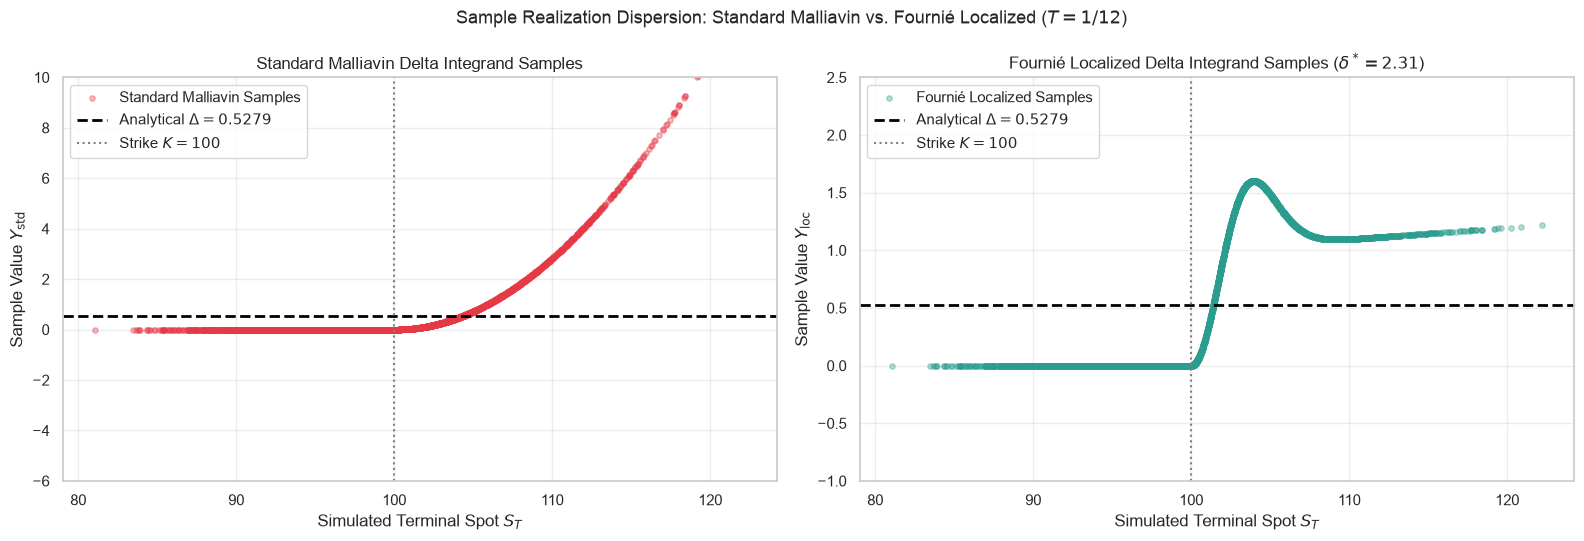

Sample Standard Deviation (Dispersion):
  Standard Malliavin Delta Std: 1.1892
  Fournié Localized Delta Std : 0.6196
  Sample Variance Reduction   : 3.68x


In [5]:
N_scatter = 5000
paths_scatter = generate_paths(T_1M, N_scatter, seed=42)
S_T_scatter = simulate_terminal_spot(S0, T_1M, r, q, sigma, paths_scatter)

# Per-path Delta samples from the library estimators
samples_std_scat = malliavin_samples_european(payoffs.call, p_1M, paths_scatter)["delta"]
samples_loc_scat = malliavin_fournier_samples_european_call(p_1M, paths_scatter, bandwidth=delta_calib)["delta"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), sharey=False)

# Standard Malliavin scatter
ax1.scatter(S_T_scatter, samples_std_scat, color="#e63946", alpha=0.35, s=15, label="Standard Malliavin Samples")
ax1.axhline(0.5279, color="black", linestyle="--", linewidth=2, label="Analytical $\\Delta = 0.5279$")
ax1.axvline(K, color="gray", linestyle=":", label=f"Strike $K = {K}$")
ax1.set_title("Standard Malliavin Delta Integrand Samples", fontsize=12)
ax1.set_xlabel("Simulated Terminal Spot $S_T$")
ax1.set_ylabel("Sample Value $Y_{\\mathrm{std}}$")
ax1.set_ylim(-6.0, 10.0)
ax1.legend(frameon=True, loc="upper left")

# Fournié Localized scatter
ax2.scatter(S_T_scatter, samples_loc_scat, color="#2a9d8f", alpha=0.35, s=15, label="Fournié Localized Samples")
ax2.axhline(0.5279, color="black", linestyle="--", linewidth=2, label="Analytical $\\Delta = 0.5279$")
ax2.axvline(K, color="gray", linestyle=":", label=f"Strike $K = {K}$")
ax2.set_title("Fournié Localized Delta Integrand Samples ($\delta^* = 2.31$)", fontsize=12)
ax2.set_xlabel("Simulated Terminal Spot $S_T$")
ax2.set_ylabel("Sample Value $Y_{\mathrm{loc}}$")
ax2.set_ylim(-1.0, 2.5)
ax2.legend(frameon=True, loc="upper left")

plt.suptitle("Sample Realization Dispersion: Standard Malliavin vs. Fournié Localized ($T = 1/12$)", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Sample Standard Deviation (Dispersion):")
print(f"  Standard Malliavin Delta Std: {np.std(samples_std_scat):.4f}")
print(f"  Fournié Localized Delta Std : {np.std(samples_loc_scat):.4f}")
print(f"  Sample Variance Reduction   : {(np.var(samples_std_scat) / np.var(samples_loc_scat)):.2f}x")


---
## 3. Option Valuation & Greeks Benchmarking: Analytical vs. Standard vs. Fournié

We compute the complete valuation profile (Price, Delta, Gamma, Vega) of the 1-month European Call using:
1. **Analytical Formula:** Exact closed-form Black-Scholes formulas.
2. **Standard Malliavin ($N = 1,000,000$):** Monte Carlo simulation with exact polynomial Malliavin weights.
3. **Fournié Localized Malliavin ($N = 1,000,000$):** Monte Carlo simulation with calibrated Gaussian cutoff $\delta^* \approx 2.31$.

For both Monte Carlo estimators, we compute the exact sample standard error:
$$\text{SE}(\hat{\theta}) = \frac{s}{\sqrt{N}}$$
and 95% confidence intervals $[\hat{\theta} - 1.96 \cdot \text{SE}, \; \hat{\theta} + 1.96 \cdot \text{SE}]$. 

In [6]:
N_benchmark = 1_000_000
seed_bench = 1984

# 1. Analytical Benchmark
d1_val = d1(S0, K, T_1M, r, q, sigma)
d2_val = d2(S0, K, T_1M, r, q, sigma)
analytic_price = S0 * np.exp(-q * T_1M) * norm.cdf(d1_val) - K * np.exp(-r * T_1M) * norm.cdf(d2_val)
analytic_greeks = greeks_european_call(p_1M)

# 2. Monte Carlo simulation paths
paths_bench = generate_paths(T_1M, N_benchmark, seed=seed_bench)
S_T_bench = simulate_terminal_spot(S0, T_1M, r, q, sigma, paths_bench)

# Prices
mc_price_samples = np.exp(-r * T_1M) * payoffs.call(S_T_bench, p_1M)
price_mc = np.mean(mc_price_samples)
price_mc_se = np.std(mc_price_samples) / np.sqrt(N_benchmark)

# Standard Malliavin Greeks & SE
std_bench = malliavin_samples_european(payoffs.call, p_1M, paths_bench)
std_d_samples, std_g_samples, std_v_samples = std_bench["delta"], std_bench["gamma"], std_bench["vega"]

std_d, std_d_se = np.mean(std_d_samples), np.std(std_d_samples) / np.sqrt(N_benchmark)
std_g, std_g_se = np.mean(std_g_samples), np.std(std_g_samples) / np.sqrt(N_benchmark)
std_v, std_v_se = np.mean(std_v_samples), np.std(std_v_samples) / np.sqrt(N_benchmark)

# Fournié localized Greeks & SE (one coupled bandwidth for all Greeks, general Gamma formula)
four_bench = malliavin_fournier_samples_european_call(p_1M, paths_bench, bandwidth=delta_calib)
four_d_samples, four_g_samples, four_v_samples = four_bench["delta"], four_bench["gamma"], four_bench["vega"]

four_d, four_d_se = np.mean(four_d_samples), np.std(four_d_samples) / np.sqrt(N_benchmark)
four_g, four_g_se = np.mean(four_g_samples), np.std(four_g_samples) / np.sqrt(N_benchmark)
four_v, four_v_se = np.mean(four_v_samples), np.std(four_v_samples) / np.sqrt(N_benchmark)

# Assemble summary table
summary_data = [
    {
        "Method": "Analytical Black-Scholes",
        "Price": analytic_price,
        "Delta": analytic_greeks["delta"],
        "Delta SE": 0.0,
        "Delta Rel Err (%)": 0.0,
        "Gamma": analytic_greeks["gamma"],
        "Gamma SE": 0.0,
        "Gamma Rel Err (%)": 0.0,
        "Vega": analytic_greeks["vega"],
        "Vega SE": 0.0,
        "Vega Rel Err (%)": 0.0,
    },
    {
        "Method": "Standard Malliavin (MC)",
        "Price": price_mc,
        "Delta": std_d,
        "Delta SE": std_d_se,
        "Delta Rel Err (%)": abs(std_d - analytic_greeks["delta"]) / analytic_greeks["delta"] * 100.0,
        "Gamma": std_g,
        "Gamma SE": std_g_se,
        "Gamma Rel Err (%)": abs(std_g - analytic_greeks["gamma"]) / analytic_greeks["gamma"] * 100.0,
        "Vega": std_v,
        "Vega SE": std_v_se,
        "Vega Rel Err (%)": abs(std_v - analytic_greeks["vega"]) / analytic_greeks["vega"] * 100.0,
    },
    {
        "Method": f"Fournié Localized (MC, $\delta^*={delta_calib:.2f}$)",
        "Price": price_mc,
        "Delta": four_d,
        "Delta SE": four_d_se,
        "Delta Rel Err (%)": abs(four_d - analytic_greeks["delta"]) / analytic_greeks["delta"] * 100.0,
        "Gamma": four_g,
        "Gamma SE": four_g_se,
        "Gamma Rel Err (%)": abs(four_g - analytic_greeks["gamma"]) / analytic_greeks["gamma"] * 100.0,
        "Vega": four_v,
        "Vega SE": four_v_se,
        "Vega Rel Err (%)": abs(four_v - analytic_greeks["vega"]) / analytic_greeks["vega"] * 100.0,
    },
]

df_summary = pd.DataFrame(summary_data)
display(df_summary)

print(f"\nVariance Reduction Multipliers (Standard vs. Fournié, N = {N_benchmark:_}):")
print(f"  Delta Variance Reduction : {(std_d_se**2 / four_d_se**2):.2f}x (SE reduced by {(std_d_se / four_d_se):.2f}x)")
print(f"  Gamma Variance Reduction : {(std_g_se**2 / four_g_se**2):.2f}x (SE reduced by {(std_g_se / four_g_se):.2f}x)")
print(f"  Vega Variance Reduction  : {(std_v_se**2 / four_v_se**2):.2f}x (SE reduced by {(std_v_se / four_v_se):.2f}x)")


<>:64: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:64: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/var/folders/z3/4jhkb20n36z663jvlvmzxhj00000gn/T/ipykernel_37310/4047011108.py:64: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  "Method": f"Fournié Localized (MC, $\delta^*={delta_calib:.2f}$)",


,Method,Price,Delta,Delta SE,Delta Rel Err (%),Gamma,Gamma SE,Gamma Rel Err (%),Vega,Vega SE,Vega Rel Err (%)
0,Analytical Black-Scholes,2.423057,0.527886,0.000000,0.000000,0.068804,0.000000,0.000000,11.467392,0.000000,0.000000
1,Standard Malliavin (MC),2.425249,0.527661,0.001195,0.042646,0.068433,0.000402,0.539198,11.405560,0.066947,0.539198
2,"Fournié Localized (MC, $\delta^*=2.31$)",2.425249,0.528792,0.000623,0.171748,0.068694,0.000196,0.159756,11.481027,0.019331,0.118906



Variance Reduction Multipliers (Standard vs. Fournié, N = 1_000_000):
  Delta Variance Reduction : 3.68x (SE reduced by 1.92x)
  Gamma Variance Reduction : 4.21x (SE reduced by 2.05x)
  Vega Variance Reduction  : 11.99x (SE reduced by 3.46x)


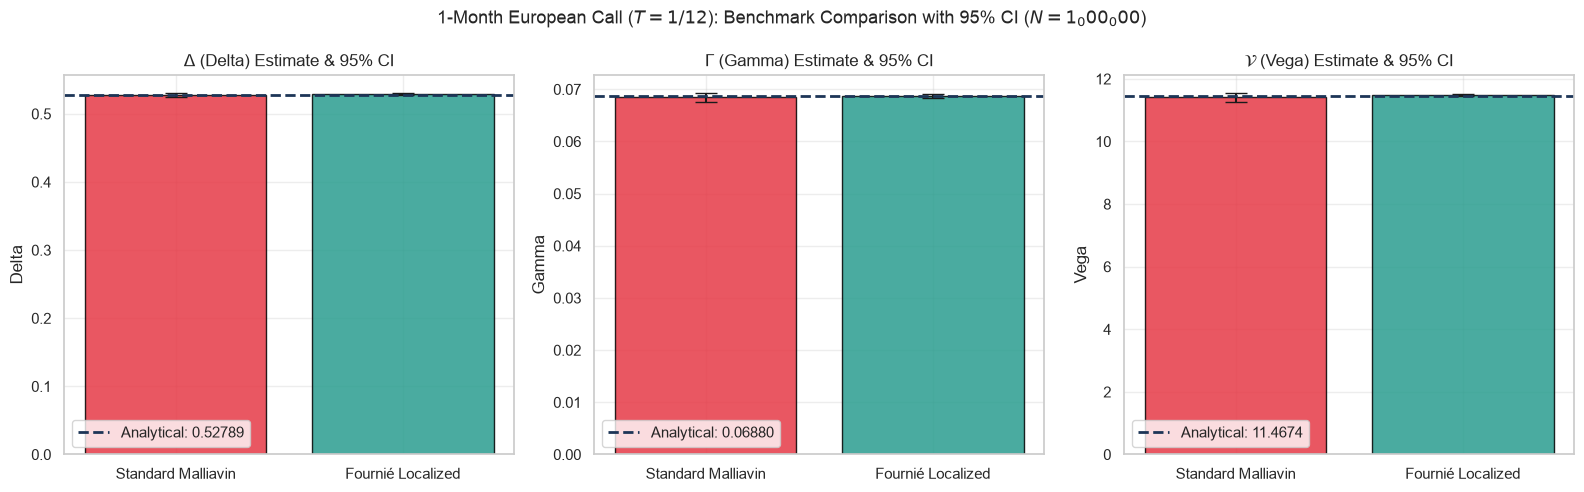

In [7]:
# Visual Greek Comparison Bar Chart with Error Bars
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
methods = ["Standard Malliavin", "Fournié Localized"]
colors_bar = ["#e63946", "#2a9d8f"]

# Delta
axes[0].bar(methods, [std_d, four_d], yerr=[1.96 * std_d_se, 1.96 * four_d_se],
            capsize=8, color=colors_bar, alpha=0.85, edgecolor="black")
axes[0].axhline(analytic_greeks["delta"], color="#1d3557", linestyle="--", linewidth=2,
                label=f"Analytical: {analytic_greeks['delta']:.5f}")
axes[0].set_title(r"$\Delta$ (Delta) Estimate & 95% CI")
axes[0].set_ylabel("Delta")
axes[0].legend(frameon=True)

# Gamma
axes[1].bar(methods, [std_g, four_g], yerr=[1.96 * std_g_se, 1.96 * four_g_se],
            capsize=8, color=colors_bar, alpha=0.85, edgecolor="black")
axes[1].axhline(analytic_greeks["gamma"], color="#1d3557", linestyle="--", linewidth=2,
                label=f"Analytical: {analytic_greeks['gamma']:.5f}")
axes[1].set_title(r"$\Gamma$ (Gamma) Estimate & 95% CI")
axes[1].set_ylabel("Gamma")
axes[1].legend(frameon=True)

# Vega
axes[2].bar(methods, [std_v, four_v], yerr=[1.96 * std_v_se, 1.96 * four_v_se],
            capsize=8, color=colors_bar, alpha=0.85, edgecolor="black")
axes[2].axhline(analytic_greeks["vega"], color="#1d3557", linestyle="--", linewidth=2,
                label=f"Analytical: {analytic_greeks['vega']:.4f}")
axes[2].set_title(r"$\mathcal{V}$ (Vega) Estimate & 95% CI")
axes[2].set_ylabel("Vega")
axes[2].legend(frameon=True)

plt.suptitle(f"1-Month European Call ($T = 1/12$): Benchmark Comparison with 95% CI ($N = {N_benchmark:_}$)", fontsize=13)
plt.tight_layout()
plt.show()


---
## 4. Playing with the Delta Gap ($\delta$) & Smoothing Functions: Mapping the Convex Variance Minimum

We sweep the bandwidth parameter $\delta$ across a wide range:
$$\delta \in [0.25, 0.50, 0.75, 1.0, 1.5, 2.0, 2.3094, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 15.0]$$
across all 5 smoothing cutoff functions (`gaussian`, `cubic`, `cosine`, `quintic`, `cauchy`).

#### Two Opposing Forces Create a U-Shaped Variance Curve:
1. **As $\delta \to 0$ (Overly Narrow Window):**
   The smoothing window shrinks to zero width. The boundary derivative spikes as $\psi'(S_T) \sim \mathcal{O}(1/\delta)$, injecting massive sample variance at the transition boundaries.
2. **As $\delta \to \infty$ (Overly Broad Window):**
   The smoothing window engulfs the entire probability density of terminal prices ($\psi \to 1$). The estimator degenerates into **Standard Malliavin**, inheriting the full quadratic weight variance.
3. **The Convex Minimum ($\delta^*$):**
   A unique, optimal bandwidth exists in between. The theoretical rule states $\delta^* = 0.40 S_0 \sigma \sqrt{T} \approx 2.31$. What does the empirical data show?

In [8]:
deltas_grid = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.3094, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 15.0]
cutoff_types = ["gaussian", "cubic", "cosine", "quintic", "cauchy"]

# Re-use pre-generated paths to eliminate Monte Carlo sampling noise across delta evaluations
N_grid = 250_000
paths_grid = generate_paths(T_1M, N_grid, seed=42)

# Standard Malliavin reference variances
std_grid = malliavin_samples_european(payoffs.call, p_1M, paths_grid)
var_std_delta = np.var(std_grid["delta"])
var_std_gamma = np.var(std_grid["gamma"])
var_std_vega  = np.var(std_grid["vega"])

grid_records = []

for ctype in cutoff_types:
    for d in deltas_grid:
        loc = malliavin_fournier_samples_european_call(p_1M, paths_grid, cutoff_type=ctype, bandwidth=d)
        loc_d_s, loc_g_s, loc_v_s = loc["delta"], loc["gamma"], loc["vega"]

        v_delta = float(np.var(loc_d_s))
        v_gamma = float(np.var(loc_g_s))
        v_vega  = float(np.var(loc_v_s))
        
        grid_records.append({
            "cutoff_type": ctype,
            "delta": d,
            "delta_mean": float(np.mean(loc_d_s)),
            "delta_var": v_delta,
            "gamma_mean": float(np.mean(loc_g_s)),
            "gamma_var": v_gamma,
            "vega_mean": float(np.mean(loc_v_s)),
            "vega_var": v_vega,
            "delta_reduction": var_std_delta / v_delta,
            "gamma_reduction": var_std_gamma / v_gamma,
            "vega_reduction": var_std_vega / v_vega,
        })

df_grid = pd.DataFrame(grid_records)

# Find optimal delta per function minimizing variance for each Greek
opt_records = []
for ctype in cutoff_types:
    sub = df_grid[df_grid["cutoff_type"] == ctype]
    idx_d = sub["delta_var"].idxmin()
    idx_g = sub["gamma_var"].idxmin()
    idx_v = sub["vega_var"].idxmin()
    row_d = sub.loc[idx_d]
    row_g = sub.loc[idx_g]
    row_v = sub.loc[idx_v]
    opt_records.append({
        "Cutoff": ctype.capitalize(),
        "Best $\\delta^*_\\Delta$": row_d["delta"],
        "$\\Delta$ Var (Redux)": f"{row_d['delta_var']:.4f} ({row_d['delta_reduction']:.2f}x)",
        "Best $\\delta^*_\\Gamma$": row_g["delta"],
        "$\\Gamma$ Var (Redux)": f"{row_g['gamma_var']:.5f} ({row_g['gamma_reduction']:.2f}x)",
        "Best $\\delta^*_\\mathcal{V}$": row_v["delta"],
        "$\\mathcal{V}$ Var (Redux)": f"{row_v['vega_var']:.2f} ({row_v['vega_reduction']:.2f}x)",
    })

df_opt = pd.DataFrame(opt_records)
print("=== Optimal Empirical Bandwidths Across Smoothing Classes ===")
display(df_opt)


=== Optimal Empirical Bandwidths Across Smoothing Classes ===


,Cutoff,Best $\delta^*_\Delta$,$\Delta$ Var (Redux),Best $\delta^*_\Gamma$,$\Gamma$ Var (Redux),Best $\delta^*_\mathcal{V}$,$\mathcal{V}$ Var (Redux)
0,Gaussian,0.25,0.2845 (5.17x),6.0,0.00701 (25.21x),0.25,327.67 (14.98x)
1,Cubic,0.25,0.2790 (5.27x),15.0,0.01092 (16.18x),0.50,327.67 (14.98x)
2,Cosine,0.25,0.2791 (5.27x),15.0,0.01142 (15.48x),0.50,327.67 (14.98x)
3,Quintic,0.25,0.2798 (5.26x),15.0,0.01600 (11.04x),0.75,327.67 (14.98x)
4,Cauchy,0.25,0.2801 (5.25x),6.0,0.00636 (27.77x),0.25,329.00 (14.92x)


<>:13: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:14: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:18: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:18: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:13: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:14: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:18: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences wil

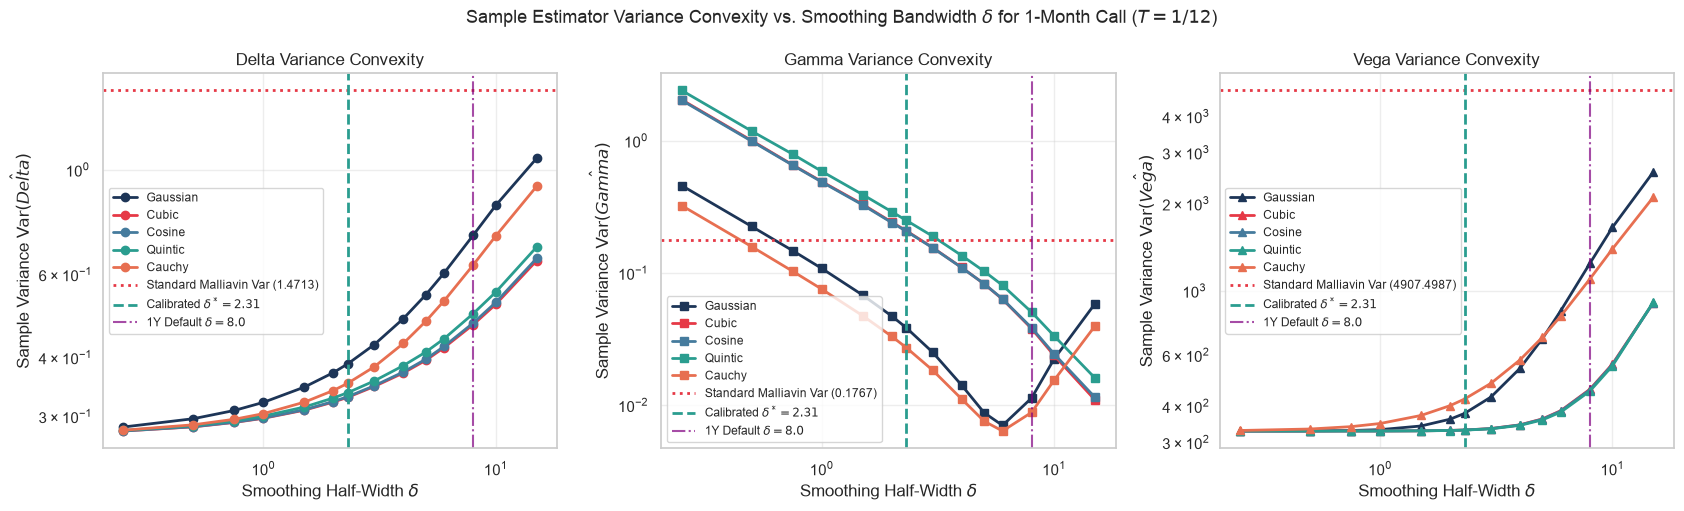

Impact of Proper Delta Gap Scaling (Gaussian Cutoff):
  At Calibrated 1M Gap (delta = 2.31): Delta Var = 0.3874, Gamma Var = 0.0385, Vega Var = 376.79
  At Unscaled 1Y Gap   (delta = 8.00): Delta Var = 0.7260, Gamma Var = 0.0113, Vega Var = 1242.43
  Delta Variance Penalty if unscaled: 1.87x higher variance!
  Gamma Variance Penalty if unscaled: 0.29x higher variance!
  Vega Variance Penalty if unscaled : 3.30x higher variance!


In [9]:
# Visualizing Variance Convexity Across Cutoff Types and Gap Bandwidths
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

for ctype in cutoff_types:
    sub = df_grid[df_grid["cutoff_type"] == ctype].sort_values("delta")
    axes[0].plot(sub["delta"], sub["delta_var"], marker="o", color=colors_map[ctype], label=ctype.capitalize(), linewidth=2)
    axes[1].plot(sub["delta"], sub["gamma_var"], marker="s", color=colors_map[ctype], label=ctype.capitalize(), linewidth=2)
    axes[2].plot(sub["delta"], sub["vega_var"], marker="^", color=colors_map[ctype], label=ctype.capitalize(), linewidth=2)

# Reference lines
for i, (ax, g_name, v_std) in enumerate(zip(axes, ["Delta", "Gamma", "Vega"], [var_std_delta, var_std_gamma, var_std_vega])):
    ax.axhline(v_std, color="#e63946", linestyle=":", linewidth=2, label=f"Standard Malliavin Var ({v_std:.4f})")
    ax.axvline(delta_calib, color="#2a9d8f", linestyle="--", linewidth=2, label=f"Calibrated $\delta^* = {delta_calib:.2f}$")
    ax.axvline(8.0, color="purple", linestyle="-.", alpha=0.7, label="1Y Default $\delta = 8.0$")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Smoothing Half-Width $\delta$")
    ax.set_ylabel(f"Sample Variance $\operatorname{{Var}}(\hat{{{g_name}}})$")
    ax.set_title(f"{g_name} Variance Convexity")
    ax.legend(frameon=True, fontsize=8.5)

plt.suptitle(r"Sample Estimator Variance Convexity vs. Smoothing Bandwidth $\delta$ for 1-Month Call ($T = 1/12$)", fontsize=13)
plt.tight_layout()
plt.show()

# Print comparison: calibrated delta vs unscaled 1Y default
sub_calib = df_grid[(df_grid["cutoff_type"] == "gaussian") & (np.isclose(df_grid["delta"], delta_calib))].iloc[0]
sub_8 = df_grid[(df_grid["cutoff_type"] == "gaussian") & (df_grid["delta"] == 8.0)].iloc[0]

print("Impact of Proper Delta Gap Scaling (Gaussian Cutoff):")
print(f"  At Calibrated 1M Gap (delta = {delta_calib:.2f}): Delta Var = {sub_calib['delta_var']:.4f}, Gamma Var = {sub_calib['gamma_var']:.4f}, Vega Var = {sub_calib['vega_var']:.2f}")
print(f"  At Unscaled 1Y Gap   (delta = 8.00): Delta Var = {sub_8['delta_var']:.4f}, Gamma Var = {sub_8['gamma_var']:.4f}, Vega Var = {sub_8['vega_var']:.2f}")
print(f"  Delta Variance Penalty if unscaled: {(sub_8['delta_var'] / sub_calib['delta_var']):.2f}x higher variance!")
print(f"  Gamma Variance Penalty if unscaled: {(sub_8['gamma_var'] / sub_calib['gamma_var']):.2f}x higher variance!")
print(f"  Vega Variance Penalty if unscaled : {(sub_8['vega_var'] / sub_calib['vega_var']):.2f}x higher variance!")


---
### 4.2 Dedicated Vega ($\mathcal{V}$) Gap Analysis & Fournié Localization Anatomy

#### Mathematical Anatomy of Fournié Localized Vega:
Under the Black-Scholes diffusion, the pathwise derivative of terminal spot with respect to volatility $\sigma$ is:
$$\frac{\partial S_T}{\partial \sigma} = S_T (W_T - \sigma T)$$

Applying Fournié localization (Theorem 2.3) with cutoff $\psi(S_T)$ and boundary derivative $\psi'(S_T)$ yields:
$$Y^\mathcal{V}_{\text{loc}} = e^{-rT} \left[ g(S_T)\left(\psi(S_T) \pi^\mathcal{V} - \psi'(S_T) S_T (W_T - \sigma T)\right) + \mathbf{1}_{S_T > K} (1 - \psi(S_T)) S_T (W_T - \sigma T) \right]$$
where the standard Malliavin Vega weight is $\pi^\mathcal{V} = \frac{W_T^2 - \sigma T W_T - T}{\sigma T}$.

#### Payoff Topology: Why Vega Behaves Like Delta ($C^0$ Kink) Rather Than Gamma ($C^{-1}$ Jump):
1. **Delta & Vega ($C^0$ Continuity):**
   Both sensitivities differentiate the continuous call payoff $g(S_T) = (S_T - K)^+$.
   As $S_T \to K$, $g(S_T) \to 0$. Therefore, in the boundary term:
   $$g(S_T) \psi'(S_T) = (S_T - K)^+ \cdot \left(-\frac{S_T - K}{\delta^2}\right) \exp\left(-\frac{(S_T - K)^2}{2\delta^2}\right) \to 0$$
   The boundary derivative $-\psi' \sim 1/\delta$ is naturally mitigated by the vanishing payoff $(S_T - K) \to 0$.
   Hence, as $\delta$ is reduced, the boundary term remains uniformly bounded and does NOT inject large variance!
2. **Gamma ($C^{-1}$ Step Discontinuity):**
   In the localized Gamma, the term $-2\,\mathbf{1}_{S_T > K}\,\psi'(S_T) (S_T/S_0)^2$ contains the step $g'(S_T) = \mathbf{1}_{S_T > K}$, which jumps by $+1$ at $K$ and does NOT vanish.
   It has no $(S_T - K)$ dampener and grows as $\mathcal{O}(1/\delta)$ when $\delta \to 0$.
   Therefore, **Gamma strictly requires a wider bandwidth ($\delta_\Gamma^* \approx 0.50 S_0 \sigma \sqrt{T} \approx 2.89$)** to keep boundary variance under control.
3. **The Scaling Rule for Vega:**
   Because Vega shares the continuous kink topology of Delta, its variance is minimized when the pathwise derivative is leveraged over the largest possible domain without boundary instability:
   $$\delta^*_\mathcal{V} \approx 0.20 \times S_0 \sigma \sqrt{T} \approx 1.15 \quad (\text{for } T = 1/12)$$
   $$\delta^*_\mathcal{V} \approx 4.0 \quad (\text{for } T = 1.0)$$

Below, we visualize the Monte Carlo sample dispersion for Vega and sweep $\delta$ across a fine grid!

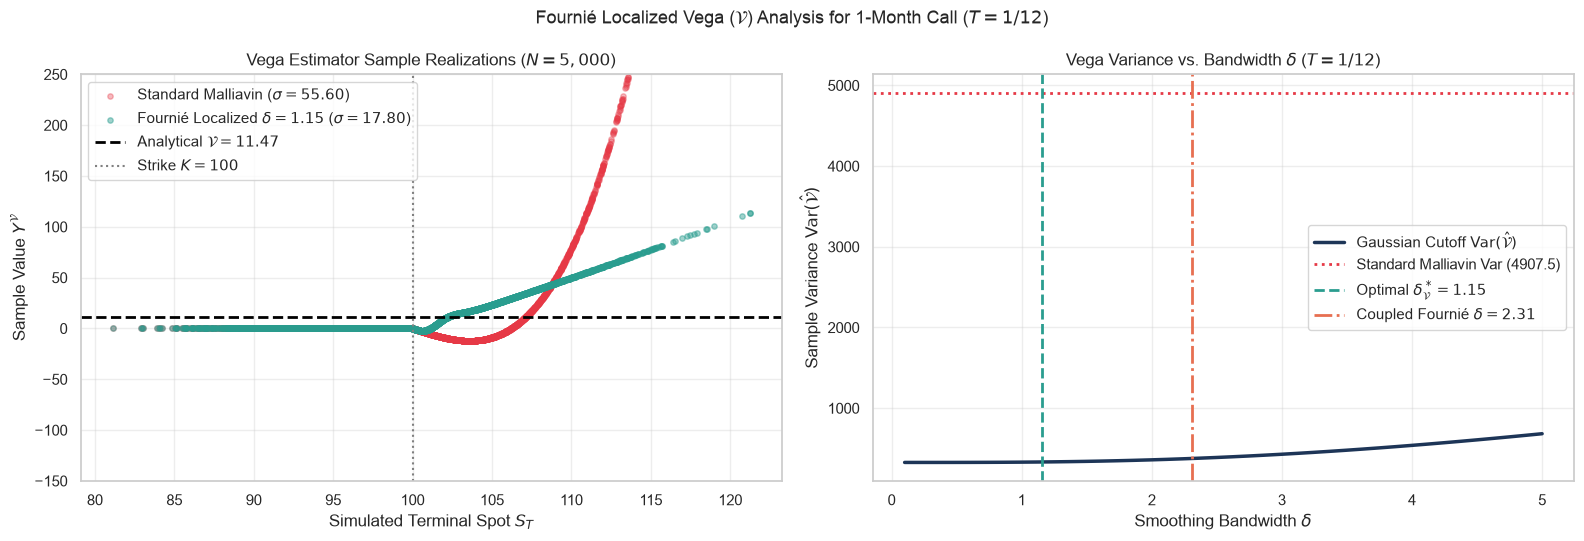

Vega Variance Comparison (N = 250_000):
  Standard Malliavin Vega Variance: 4907.50
  Coupled Fournié (delta = 2.31) Vega Variance: 376.79
  Optimal Vega (delta = 1.15) Vega Variance : 327.67
  Variance Reduction vs. Standard: 14.98x
  Extra Reduction from Decoupling vs. Coupled: 15.0%


In [10]:
# Vega Sample Realization Dispersion & Bandwidth Sweep
N_scat_v = 5000
paths_v = generate_paths(T_1M, N_scat_v, seed=101)
S_T_v = simulate_terminal_spot(S0, T_1M, r, q, sigma, paths_v)

# Standard Malliavin and Fournié Vega samples (default Vega bandwidth 0.20 * S0 * sigma * sqrt(T) ~ 1.15)
delta_vega_opt = fournier_bandwidths(p_1M)["vega"]
samples_std_v = malliavin_samples_european(payoffs.call, p_1M, paths_v)["vega"]
samples_loc_v = malliavin_fournier_samples_european_call(p_1M, paths_v, bandwidth=delta_vega_opt)["vega"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Panel 1: Sample Scatter Plot
axes[0].scatter(S_T_v, samples_std_v, color="#e63946", alpha=0.35, s=15, label=rf"Standard Malliavin ($\sigma = {np.std(samples_std_v):.2f}$)")
axes[0].scatter(S_T_v, samples_loc_v, color="#2a9d8f", alpha=0.45, s=15, label=rf"Fournié Localized $\delta = {delta_vega_opt:.2f}$ ($\sigma = {np.std(samples_loc_v):.2f}$)")
axes[0].axhline(analytic_greeks["vega"], color="black", linestyle="--", linewidth=2, label=rf"Analytical $\mathcal{{V}} = {analytic_greeks['vega']:.2f}$")
axes[0].axvline(K, color="gray", linestyle=":", label=f"Strike $K = {K}$")
axes[0].set_title(r"Vega Estimator Sample Realizations ($N = 5,000$)", fontsize=12)
axes[0].set_xlabel("Simulated Terminal Spot $S_T$")
axes[0].set_ylabel(r"Sample Value $Y^\mathcal{V}$")
axes[0].set_ylim(-150, 250)
axes[0].legend(frameon=True, loc="upper left")

# Panel 2: Fine Grid Vega Variance vs Delta
deltas_fine = np.linspace(0.1, 5.0, 40)
vars_vega_fine = []
for d_val in deltas_fine:
    v_samples = malliavin_fournier_samples_european_call(p_1M, paths_grid, bandwidth=float(d_val))["vega"]
    vars_vega_fine.append(np.var(v_samples))

axes[1].plot(deltas_fine, vars_vega_fine, color="#1d3557", linewidth=2.5, label=r"Gaussian Cutoff $\operatorname{Var}(\hat{\mathcal{V}})$")
axes[1].axhline(var_std_vega, color="#e63946", linestyle=":", linewidth=2, label=f"Standard Malliavin Var ({var_std_vega:.1f})")
axes[1].axvline(delta_vega_opt, color="#2a9d8f", linestyle="--", linewidth=2, label=rf"Optimal $\delta^*_\mathcal{{V}} = {delta_vega_opt:.2f}$")
axes[1].axvline(delta_calib, color="#e76f51", linestyle="-.", linewidth=2, label=rf"Coupled Fournié $\delta = {delta_calib:.2f}$")
axes[1].set_title(r"Vega Variance vs. Bandwidth $\delta$ ($T = 1/12$)", fontsize=12)
axes[1].set_xlabel(r"Smoothing Bandwidth $\delta$")
axes[1].set_ylabel(r"Sample Variance $\operatorname{Var}(\hat{\mathcal{V}})$")
axes[1].legend(frameon=True)

plt.suptitle(r"Fournié Localized Vega ($\mathcal{V}$) Analysis for 1-Month Call ($T = 1/12$)", fontsize=13)
plt.tight_layout()
plt.show()

sub_v_calib = df_grid[(df_grid["cutoff_type"] == "gaussian") & (np.isclose(df_grid["delta"], delta_calib))]["vega_var"].iloc[0]
best_v_fine = min(vars_vega_fine)

print(f"Vega Variance Comparison (N = {N_grid:_}):")
print(f"  Standard Malliavin Vega Variance: {var_std_vega:.2f}")
print(f"  Coupled Fournié (delta = {delta_calib:.2f}) Vega Variance: {sub_v_calib:.2f}")
print(f"  Optimal Vega (delta = {delta_vega_opt:.2f}) Vega Variance : {best_v_fine:.2f}")
print(f"  Variance Reduction vs. Standard: {var_std_vega / best_v_fine:.2f}x")
print(f"  Extra Reduction from Decoupling vs. Coupled: {(sub_v_calib / best_v_fine - 1) * 100:.1f}%")


---
### 4.3 Option A (Decoupled Bandwidths per Greek): The Definitive Multi-Greek Architecture

#### The Architectural Decision: Coupled vs. Decoupled Fournié Bandwidths
- **Option B (Coupled Bandwidth):**
  Uses a single scalar $\delta \approx 0.40 S_0 \sigma \sqrt{T} = 2.31$ for all Greeks ($\delta_\Delta = \delta_\Gamma = \delta_\mathcal{V} = 2.31$).
  The table below shows how this compromise compares with per-Greek bandwidths.
- **Option A (Decoupled Bandwidths in a Single MC Pass):**
  Exploits the mathematical topology of each Greek individually:
  $$\delta^*_\Delta = 0.20 \times S_0 \sigma \sqrt{T} \approx 1.15 \quad (\text{Continuous Kink } C^0)$$
  $$\delta^*_\mathcal{V} = 0.20 \times S_0 \sigma \sqrt{T} \approx 1.15 \quad (\text{Continuous Kink } C^0)$$
  $$\delta^*_\Gamma = 0.50 \times S_0 \sigma \sqrt{T} \approx 2.89 \quad (\text{Discontinuous Step } C^{-1})$$
  Paths and terminal prices $S_T$ are generated once; each extra bandwidth costs one more cutoff evaluation per path.

Below, we compare **Standard Malliavin vs. Coupled Fournié vs. Decoupled Fournié (Option A)** on $1,000,000$ Common Random Number paths!

In [11]:
# Head-to-Head Comparison: Standard vs. Coupled Fournié vs. Decoupled Option A
# Common Random Numbers (N = 1,000,000 paths)
bandwidths_opt = fournier_bandwidths(p_1M)  # (0.20, 0.50, 0.20) * S0 * sigma * sqrt(T)
delta_opt_d, delta_opt_g, delta_opt_v = bandwidths_opt["delta"], bandwidths_opt["gamma"], bandwidths_opt["vega"]

# Decoupled Option A estimators (same paths as Section 3)
decoup = malliavin_fournier_samples_european_call(p_1M, paths_bench, bandwidth=bandwidths_opt)
decoup_d_samples, decoup_g_samples, decoup_v_samples = decoup["delta"], decoup["gamma"], decoup["vega"]

# Compute metrics
var_std_d, var_std_g, var_std_v = np.var(std_d_samples), np.var(std_g_samples), np.var(std_v_samples)
var_coup_d, var_coup_g, var_coup_v = np.var(four_d_samples), np.var(four_g_samples), np.var(four_v_samples)
var_decoup_d, var_decoup_g, var_decoup_v = np.var(decoup_d_samples), np.var(decoup_g_samples), np.var(decoup_v_samples)

se_decoup_d = np.sqrt(var_decoup_d / N_benchmark)
se_decoup_g = np.sqrt(var_decoup_g / N_benchmark)
se_decoup_v = np.sqrt(var_decoup_v / N_benchmark)

table_decoup = [
    {
        "Greek": "Delta (Δ)",
        "Analytical": analytic_greeks["delta"],
        "Std Malliavin Var": var_std_d,
        "Coupled Fournié (δ=2.31) Var": var_coup_d,
        "Option A Decoupled (δ=1.15) Var": var_decoup_d,
        "Redux vs Std (Coupled)": f"{var_std_d / var_coup_d:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_d / var_decoup_d:.2f}x",
        "Option A Gain vs Coupled": f"{(var_coup_d / var_decoup_d - 1) * 100:+.1f}%",
    },
    {
        "Greek": "Gamma (Γ)",
        "Analytical": analytic_greeks["gamma"],
        "Std Malliavin Var": var_std_g,
        "Coupled Fournié (δ=2.31) Var": var_coup_g,
        "Option A Decoupled (δ=2.89) Var": var_decoup_g,
        "Redux vs Std (Coupled)": f"{var_std_g / var_coup_g:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_g / var_decoup_g:.2f}x",
        "Option A Gain vs Coupled": f"{(var_coup_g / var_decoup_g - 1) * 100:+.1f}%",
    },
    {
        "Greek": "Vega (V)",
        "Analytical": analytic_greeks["vega"],
        "Std Malliavin Var": var_std_v,
        "Coupled Fournié (δ=2.31) Var": var_coup_v,
        "Option A Decoupled (δ=1.15) Var": var_decoup_v,
        "Redux vs Std (Coupled)": f"{var_std_v / var_coup_v:.2f}x",
        "Redux vs Std (Option A)": f"{var_std_v / var_decoup_v:.2f}x",
        "Option A Gain vs Coupled": f"{(var_coup_v / var_decoup_v - 1) * 100:+.1f}%",
    },
]

df_decoup_table = pd.DataFrame(table_decoup)
print("=== Head-to-Head Performance: Coupled Fournié vs. Decoupled Option A ===")
display(df_decoup_table)


=== Head-to-Head Performance: Coupled Fournié vs. Decoupled Option A ===


,Greek,Analytical,Std Malliavin Var,Coupled Fournié (δ=2.31) Var,Option A Decoupled (δ=1.15) Var,Redux vs Std (Coupled),Redux vs Std (Option A),Option A Gain vs Coupled,Option A Decoupled (δ=2.89) Var
0,Delta (Δ),0.527886,1.428014,0.388397,0.328264,3.68x,4.35x,+18.3%,NaN
1,Gamma (Γ),0.068804,0.161349,0.038339,NaN,4.21x,6.01x,+42.8%,0.026848
2,Vega (V),11.467392,4481.923190,373.669750,330.119345,11.99x,13.58x,+13.2%,NaN


<>:3: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:3: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:3: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:3: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/var/folders/z3/4jhkb20n36z663jvlvmzxhj00000gn/T/ipykernel_37310/1952712223.py:3: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  methods_cmp = ["Standard\nMalliavin", "Coupled Fournié\n($\delta = 2.31$)", "Option A Decoupled\n(Per-Greek $\delta$)"]
/var/folders/z3/4jhkb20n36z663jvlvmzx

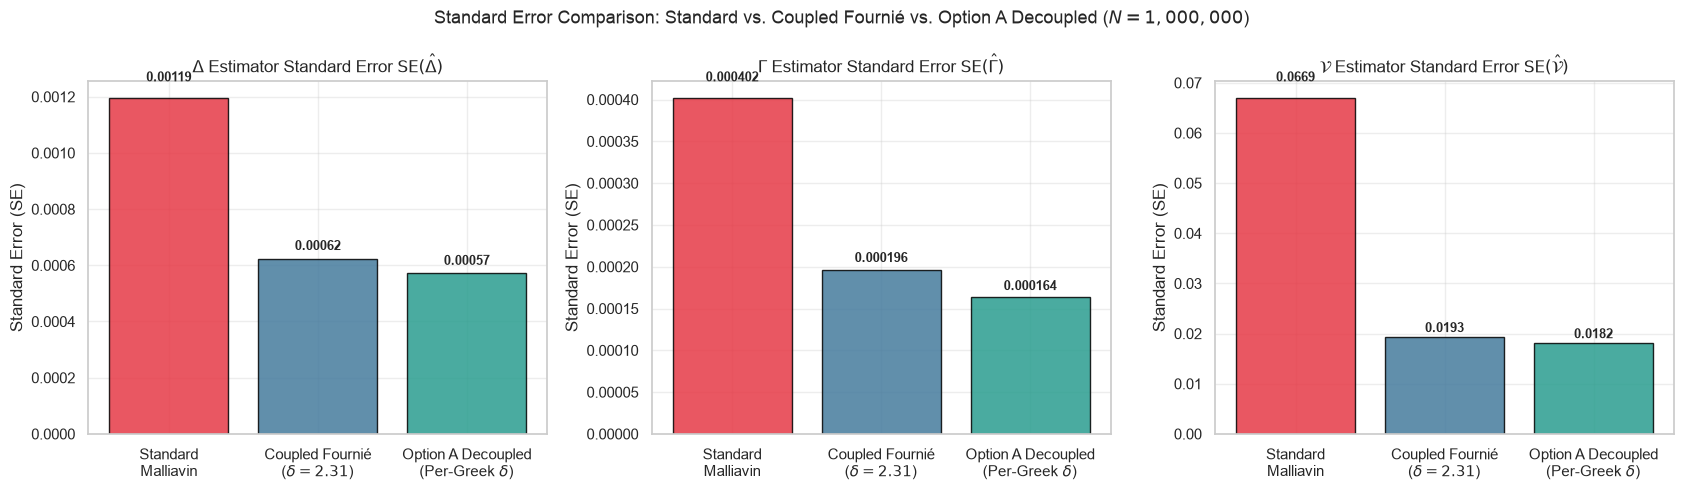

In [12]:
# Visual Comparison: Standard Error of Standard vs Coupled vs Option A Decoupled
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
methods_cmp = ["Standard\nMalliavin", "Coupled Fournié\n($\delta = 2.31$)", "Option A Decoupled\n(Per-Greek $\delta$)"]
colors_cmp = ["#e63946", "#457b9d", "#2a9d8f"]

# Delta SE
axes[0].bar(methods_cmp, [std_d_se, four_d_se, se_decoup_d], color=colors_cmp, edgecolor="black", alpha=0.85)
axes[0].set_title(r"$\Delta$ Estimator Standard Error $\mathrm{SE}(\hat{\Delta})$")
axes[0].set_ylabel("Standard Error (SE)")
for i, v in enumerate([std_d_se, four_d_se, se_decoup_d]):
    axes[0].text(i, v * 1.05, f"{v:.5f}", ha="center", fontweight="bold", fontsize=9)

# Gamma SE
axes[1].bar(methods_cmp, [std_g_se, four_g_se, se_decoup_g], color=colors_cmp, edgecolor="black", alpha=0.85)
axes[1].set_title(r"$\Gamma$ Estimator Standard Error $\mathrm{SE}(\hat{\Gamma})$")
axes[1].set_ylabel("Standard Error (SE)")
for i, v in enumerate([std_g_se, four_g_se, se_decoup_g]):
    axes[1].text(i, v * 1.05, f"{v:.6f}", ha="center", fontweight="bold", fontsize=9)

# Vega SE
axes[2].bar(methods_cmp, [std_v_se, four_v_se, se_decoup_v], color=colors_cmp, edgecolor="black", alpha=0.85)
axes[2].set_title(r"$\mathcal{V}$ Estimator Standard Error $\mathrm{SE}(\hat{\mathcal{V}})$")
axes[2].set_ylabel("Standard Error (SE)")
for i, v in enumerate([std_v_se, four_v_se, se_decoup_v]):
    axes[2].text(i, v * 1.05, f"{v:.4f}", ha="center", fontweight="bold", fontsize=9)

plt.suptitle("Standard Error Comparison: Standard vs. Coupled Fournié vs. Option A Decoupled ($N = 1,000,000$)", fontsize=13)
plt.tight_layout()
plt.show()


---
## 5. Delta Sensitivity Across Spot ($S_0$): With vs. Without Fournié Transformation

We evaluate the Delta sensitivity across a range of spot prices:
$$S_0 \in [80.0, 120.0]$$
spanning Deep Out-of-the-Money (OTM, $S_0 = 80$), At-the-Money (ATM, $S_0 = 100$), and Deep In-the-Money (ITM, $S_0 = 120$).

#### Key Theoretical Differences Across Spot:
- **Exact Black-Scholes Delta:**
  $$\Delta_{\text{BS}}(S_0) = e^{-q T} \mathcal{N}(d_1(S_0))$$
  Due to the compressed maturity ($T = 1/12$), the Delta curve forms a **very steep S-curve** around $K = 100$, transitioning sharply from $0$ to $e^{-qT} \approx 0.998$.
- **Standard Malliavin:**
  Evaluates $e^{-rT} (S_T - K)^+ \frac{W_T}{S_0 \sigma T}$. When $S_0 > K$, $(S_T - K)^+$ is large and moves with $W_T$, so the variance stays large even deep in the money.
- **Fournié Localized Malliavin:**
  When $S_0$ is away from $K$, the probability of landing inside $[K-\delta, K+\delta]$ approaches zero.
  Consequently, for deep ITM options Fournié relies almost entirely on the pathwise derivative, whose variance is small.

In [13]:
spots_sweep = np.linspace(80, 120, 25)
N_sweep = 100_000
paths_sweep = generate_paths(T_1M, N_sweep, seed=42)

bs_deltas = []
std_deltas, std_errors_std = [], []
four_deltas, std_errors_four = [], []

for s0 in spots_sweep:
    # 1. Exact Analytical Delta
    d1_s = d1(s0, K, T_1M, r, q, sigma)
    bs_deltas.append(np.exp(-q * T_1M) * norm.cdf(d1_s))
    
    p_s = {**p_1M, "S0": s0}

    # 2. Standard Malliavin
    samples_std = malliavin_samples_european(payoffs.call, p_s, paths_sweep)["delta"]
    std_deltas.append(np.mean(samples_std))
    std_errors_std.append(np.std(samples_std) / np.sqrt(N_sweep))

    # 3. Fournié localized Malliavin (coupled bandwidth scales with spot: 0.40 * S0 * sigma * sqrt(T))
    delta_s = fournier_bandwidths(p_s, coupled=True)["delta"]
    samples_four = malliavin_fournier_samples_european_call(p_s, paths_sweep, bandwidth=delta_s)["delta"]
    four_deltas.append(np.mean(samples_four))
    std_errors_four.append(np.std(samples_four) / np.sqrt(N_sweep))

bs_deltas = np.array(bs_deltas)
std_deltas = np.array(std_deltas)
std_errors_std = np.array(std_errors_std)
four_deltas = np.array(four_deltas)
std_errors_four = np.array(std_errors_four)

print("Spot sensitivity sweep completed successfully.")


Spot sensitivity sweep completed successfully.


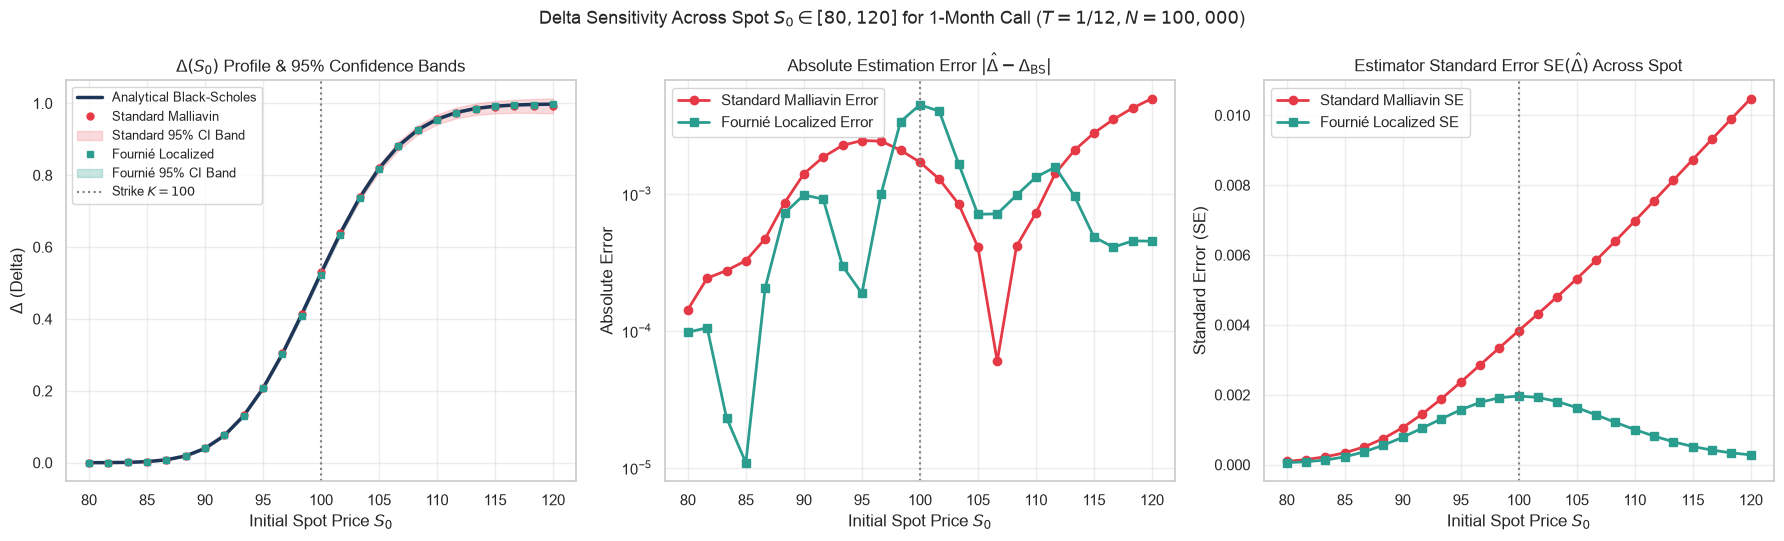

Standard Error Multipliers (Standard SE / Fournié SE):
  Deep OTM (S0 = 85.0): Standard SE = 0.00034 vs Fournié SE = 0.00022 -> Ratio: 1.52x
  ATM      (S0 = 100.0): Standard SE = 0.00383 vs Fournié SE = 0.00197 -> Ratio: 1.95x
  Deep ITM (S0 = 115.0): Standard SE = 0.00873 vs Fournié SE = 0.00052 -> Ratio: 16.75x


In [14]:
# Comprehensive 3-Panel Visual Figure: Delta across Spot S0
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1: Delta Curves with 95% Confidence Envelope
axes[0].plot(spots_sweep, bs_deltas, color="#1d3557", linewidth=2.5, label="Analytical Black-Scholes")
axes[0].plot(spots_sweep, std_deltas, "o", color="#e63946", markersize=5, label="Standard Malliavin")
axes[0].fill_between(spots_sweep, std_deltas - 1.96 * std_errors_std, std_deltas + 1.96 * std_errors_std,
                     color="#e63946", alpha=0.18, label="Standard 95% CI Band")

axes[0].plot(spots_sweep, four_deltas, "s", color="#2a9d8f", markersize=5, label="Fournié Localized")
axes[0].fill_between(spots_sweep, four_deltas - 1.96 * std_errors_four, four_deltas + 1.96 * std_errors_four,
                     color="#2a9d8f", alpha=0.25, label="Fournié 95% CI Band")

axes[0].axvline(K, color="gray", linestyle=":", label=f"Strike $K = {K}$")
axes[0].set_title(r"$\Delta(S_0)$ Profile & 95% Confidence Bands", fontsize=12)
axes[0].set_xlabel("Initial Spot Price $S_0$")
axes[0].set_ylabel(r"$\Delta$ (Delta)")
axes[0].legend(frameon=True, fontsize=9)

# Panel 2: Absolute Error vs. Analytical Benchmark
err_std = np.abs(std_deltas - bs_deltas)
err_four = np.abs(four_deltas - bs_deltas)

axes[1].plot(spots_sweep, err_std, marker="o", color="#e63946", label="Standard Malliavin Error", linewidth=2)
axes[1].plot(spots_sweep, err_four, marker="s", color="#2a9d8f", label="Fournié Localized Error", linewidth=2)
axes[1].axvline(K, color="gray", linestyle=":")
axes[1].set_title(r"Absolute Estimation Error $|\hat{\Delta} - \Delta_{\mathrm{BS}}|$", fontsize=12)
axes[1].set_xlabel("Initial Spot Price $S_0$")
axes[1].set_ylabel("Absolute Error")
axes[1].set_yscale("log")
axes[1].legend(frameon=True)

# Panel 3: Standard Error Comparison Across Spot
axes[2].plot(spots_sweep, std_errors_std, marker="o", color="#e63946", label="Standard Malliavin SE", linewidth=2)
axes[2].plot(spots_sweep, std_errors_four, marker="s", color="#2a9d8f", label="Fournié Localized SE", linewidth=2)
axes[2].axvline(K, color="gray", linestyle=":")
axes[2].set_title(r"Estimator Standard Error $\mathrm{SE}(\hat{\Delta})$ Across Spot", fontsize=12)
axes[2].set_xlabel("Initial Spot Price $S_0$")
axes[2].set_ylabel("Standard Error (SE)")
axes[2].legend(frameon=True)

plt.suptitle(r"Delta Sensitivity Across Spot $S_0 \in [80, 120]$ for 1-Month Call ($T = 1/12, N = 100,000$)", fontsize=13)
plt.tight_layout()
plt.show()

# Show SE ratios across moneyness
atm_idx = 12
itm_idx = 21
otm_idx = 3

print(f"Standard Error Multipliers (Standard SE / Fournié SE):")
print(f"  Deep OTM (S0 = {spots_sweep[otm_idx]:.1f}): Standard SE = {std_errors_std[otm_idx]:.5f} vs Fournié SE = {std_errors_four[otm_idx]:.5f} -> Ratio: {(std_errors_std[otm_idx] / std_errors_four[otm_idx]):.2f}x")
print(f"  ATM      (S0 = {spots_sweep[atm_idx]:.1f}): Standard SE = {std_errors_std[atm_idx]:.5f} vs Fournié SE = {std_errors_four[atm_idx]:.5f} -> Ratio: {(std_errors_std[atm_idx] / std_errors_four[atm_idx]):.2f}x")
print(f"  Deep ITM (S0 = {spots_sweep[itm_idx]:.1f}): Standard SE = {std_errors_std[itm_idx]:.5f} vs Fournié SE = {std_errors_four[itm_idx]:.5f} -> Ratio: {(std_errors_std[itm_idx] / std_errors_four[itm_idx]):.2f}x")


---
### 5.2 Convergence Trajectory with Sample Size $N$ ($10^3 \le N \le 10^6$)

We examine how rapidly each estimator converges to the true analytical Delta $\Delta \approx 0.527886$ as the sample size increases across 7 simulation scales:
$$N \in [1,000, \; 5,000, \; 10,000, \; 50,000, \; 100,000, \; 500,000, \; 1,000,000]$$

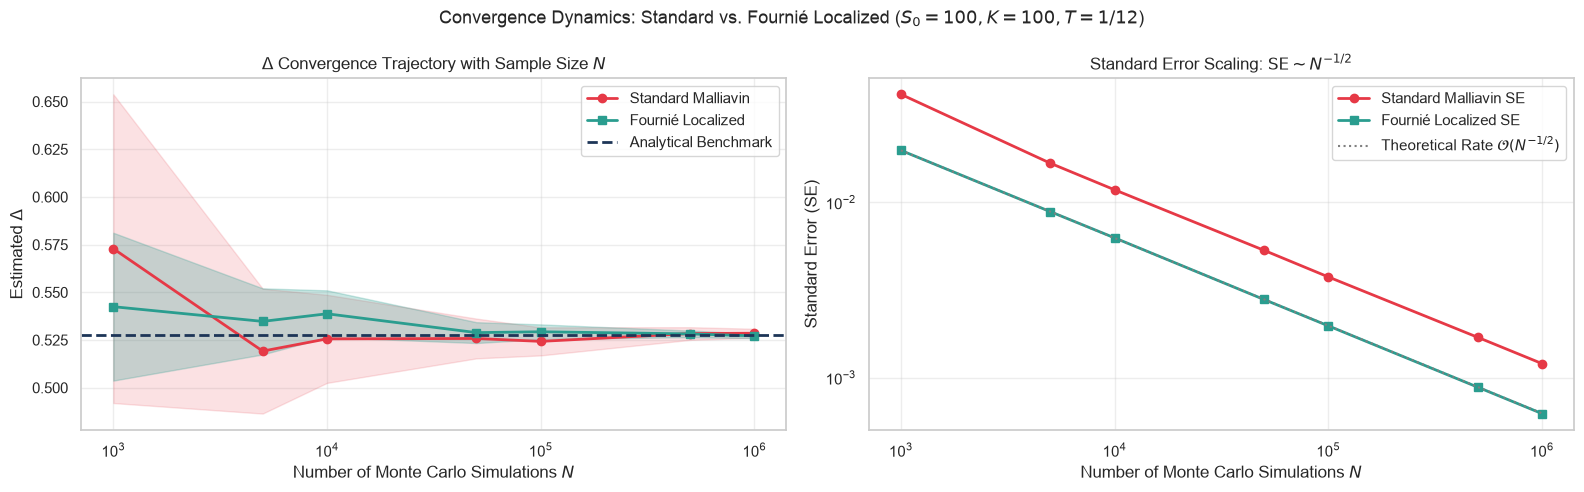

In [15]:
n_sims_list = [1_000, 5_000, 10_000, 50_000, 100_000, 500_000, 1_000_000]

conv_records = []
max_paths = generate_paths(T_1M, max(n_sims_list), seed=2026)
max_std = malliavin_samples_european(payoffs.call, p_1M, max_paths)["delta"]
max_four = malliavin_fournier_samples_european_call(p_1M, max_paths, bandwidth=delta_calib)["delta"]

for n_val in n_sims_list:
    # Nested subsets of the same paths
    s_samples = max_std[:n_val]
    f_samples = max_four[:n_val]
    
    conv_records.append({
        "N": n_val,
        "Standard Delta": np.mean(s_samples),
        "Standard SE": np.std(s_samples) / np.sqrt(n_val),
        "Fournié Delta": np.mean(f_samples),
        "Fournié SE": np.std(f_samples) / np.sqrt(n_val),
    })

df_conv = pd.DataFrame(conv_records)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Trajectory plot
ax1.plot(df_conv["N"], df_conv["Standard Delta"], marker="o", color="#e63946", label="Standard Malliavin", linewidth=2)
ax1.fill_between(df_conv["N"], df_conv["Standard Delta"] - 1.96 * df_conv["Standard SE"],
                 df_conv["Standard Delta"] + 1.96 * df_conv["Standard SE"], color="#e63946", alpha=0.15)

ax1.plot(df_conv["N"], df_conv["Fournié Delta"], marker="s", color="#2a9d8f", label="Fournié Localized", linewidth=2)
ax1.fill_between(df_conv["N"], df_conv["Fournié Delta"] - 1.96 * df_conv["Fournié SE"],
                 df_conv["Fournié Delta"] + 1.96 * df_conv["Fournié SE"], color="#2a9d8f", alpha=0.25)

ax1.axhline(analytic_greeks["delta"], color="#1d3557", linestyle="--", linewidth=2, label="Analytical Benchmark")
ax1.set_xscale("log")
ax1.set_xlabel("Number of Monte Carlo Simulations $N$")
ax1.set_ylabel(r"Estimated $\Delta$")
ax1.set_title(r"$\Delta$ Convergence Trajectory with Sample Size $N$")
ax1.legend(frameon=True)

# Standard error convergence (log-log)
ax2.plot(df_conv["N"], df_conv["Standard SE"], marker="o", color="#e63946", label="Standard Malliavin SE", linewidth=2)
ax2.plot(df_conv["N"], df_conv["Fournié SE"], marker="s", color="#2a9d8f", label="Fournié Localized SE", linewidth=2)

# Theoretical 1/sqrt(N) slope line
n_ref = np.array(n_sims_list)
ref_slope = df_conv["Fournié SE"].iloc[0] * np.sqrt(n_sims_list[0]) / np.sqrt(n_ref)
ax2.plot(n_ref, ref_slope, linestyle=":", color="gray", label=r"Theoretical Rate $\mathcal{O}(N^{-1/2})$")

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Number of Monte Carlo Simulations $N$")
ax2.set_ylabel("Standard Error (SE)")
ax2.set_title(r"Standard Error Scaling: $\mathrm{SE} \sim N^{-1/2}$")
ax2.legend(frameon=True)

plt.suptitle("Convergence Dynamics: Standard vs. Fournié Localized ($S_0 = 100, K = 100, T = 1/12$)", fontsize=13)
plt.tight_layout()
plt.show()


---
## 6. Call with Terminal Knock-Out: Combining Two Cutoffs

The payoff is $\Phi(S_T) = (S_T - K)^+ \mathbf{1}_{S_T \le H}$ with $S_0 = 100, K = 100, H = 105.25, T = 1, \sigma = 0.20$. The knock-out is checked at maturity only, so this is not a path-dependent barrier option. The payoff has a kink at $K$ and a jump of $-(H-K)$ at $H$, and its classical derivatives are $\Phi' = \mathbf{1}_{K < S_T \le H}$ and $\Phi'' = 0$ almost everywhere.

Fournié localization needs one cutoff $\psi$ that covers both singularities. The localized estimators (the same general formulas used for the call and the digital) are
$$\Delta = e^{-rT}\mathbb{E}\Big[\Phi\psi\,\pi^\Delta + \big(\Phi'(1-\psi) - \Phi\psi'\big)\tfrac{S_T}{S_0}\Big],\qquad
\Gamma = e^{-rT}\mathbb{E}\Big[\Phi\psi\,\pi^\Gamma + \big(\Phi''(1-\psi) - 2\Phi'\psi' - \Phi\psi''\big)\big(\tfrac{S_T}{S_0}\big)^2\Big],$$
and Vega as Delta with $S_T(W_T - \sigma T)$ in place of $S_T/S_0$. They drop the Dirac masses of the distributional derivatives of $\Phi$ (at $K$ and $H$). That is only valid if $\psi = 1$ and $\psi' = 0$ at both $K$ and $H$.

Two ways to build $\psi$ from bumps $\psi_K$, $\psi_H$ of half-width $\delta = 2.625 = (H-K)/2$:
- **Sum**, $\psi = \psi_K + \psi_H$. For compact cutoffs (cubic, cosine, quintic) the bumps do not overlap and the conditions hold. For the Gaussian, $\psi(K) = 1 + e^{-(H-K)^2/(2\delta^2)} = 1 + e^{-2} \approx 1.135$ and $\psi'(H) \ne 0$, so the dropped Dirac terms are not zero and **the estimator is biased**.
- **Product form**, $\psi = 1 - (1-\psi_K)(1-\psi_H)$. Equals $1$ with zero slope at both points for any cutoff, so the estimator is unbiased. For compact non-overlapping cutoffs it is identical to the sum.

The library implements both (`cutoff_combination="union"` or `"sum"`).

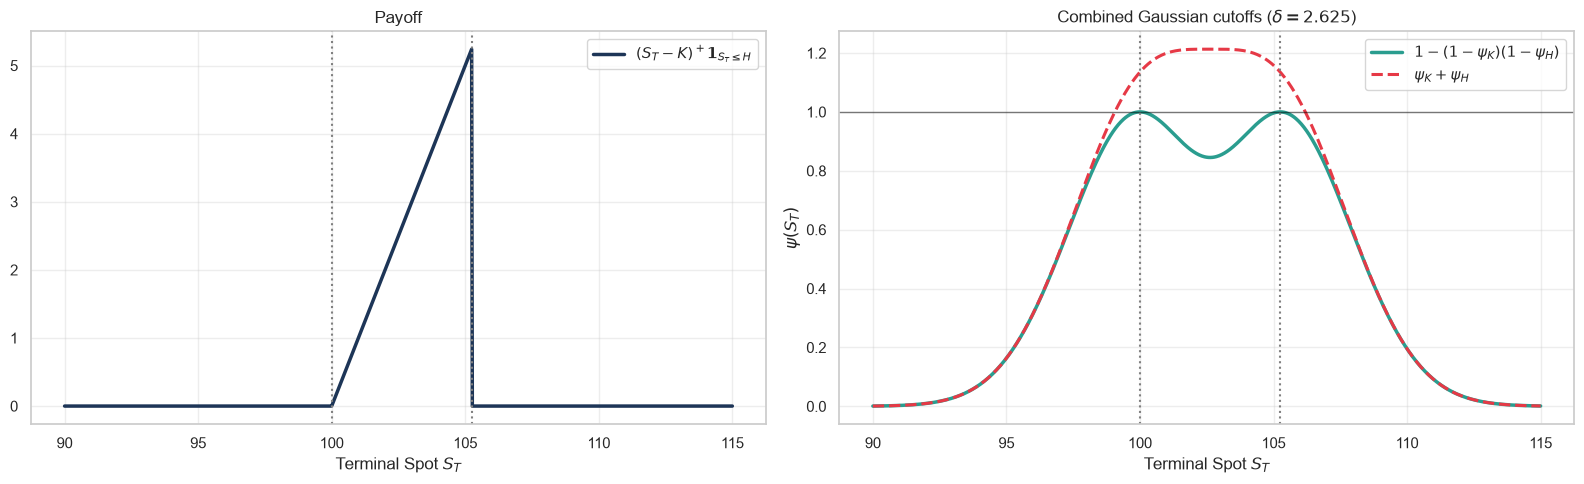

psi_K + psi_H at K = 1.1353, at H = 1.1353 (the formulas need 1)


In [16]:
# Payoff and the two combined Gaussian cutoffs around K and H
p_bar = example_european_call_terminal_knockout
S0_b, K_b, T_b, r_b, q_b, sigma_b, H_b = p_bar["S0"], p_bar["K"], p_bar["T"], p_bar["r"], p_bar["q"], p_bar["sigma"], p_bar["H"]
delta_b = (H_b - K_b) / 2.0

s_b = np.linspace(90, 115, 1000)
payoff_b = np.maximum(s_b - K_b, 0.0) * (s_b <= H_b)
psi_k, _ = get_cutoff(s_b, K_b, bandwidth=delta_b, cutoff_type="gaussian")
psi_h, _ = get_cutoff(s_b, H_b, bandwidth=delta_b, cutoff_type="gaussian")
psi_sum = psi_k + psi_h
psi_union = 1.0 - (1.0 - psi_k) * (1.0 - psi_h)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(16, 5))
ax_a.plot(s_b, payoff_b, color="#1d3557", linewidth=2.5, label=r"$(S_T - K)^+ \mathbf{1}_{S_T \leq H}$")
ax_a.axvline(K_b, color="gray", linestyle=":")
ax_a.axvline(H_b, color="gray", linestyle=":")
ax_a.set_title("Payoff")
ax_a.set_xlabel("Terminal Spot $S_T$")
ax_a.legend(frameon=True)

ax_b.plot(s_b, psi_union, color="#2a9d8f", linewidth=2.5, label=r"$1 - (1-\psi_K)(1-\psi_H)$")
ax_b.plot(s_b, psi_sum, color="#e63946", linestyle="--", linewidth=2.2, label=r"$\psi_K + \psi_H$")
ax_b.axhline(1.0, color="black", linewidth=1, alpha=0.5)
for x in (K_b, H_b):
    ax_b.axvline(x, color="gray", linestyle=":")
ax_b.set_title(rf"Combined Gaussian cutoffs ($\delta = {delta_b}$)")
ax_b.set_xlabel("Terminal Spot $S_T$")
ax_b.set_ylabel(r"$\psi(S_T)$")
ax_b.legend(frameon=True)
plt.tight_layout()
plt.show()

at_points = np.array([K_b, H_b])
psi_sum_pts = (get_cutoff(at_points, K_b, bandwidth=delta_b, cutoff_type="gaussian")[0]
               + get_cutoff(at_points, H_b, bandwidth=delta_b, cutoff_type="gaussian")[0])
print(f"psi_K + psi_H at K = {psi_sum_pts[0]:.4f}, at H = {psi_sum_pts[1]:.4f} (the formulas need 1)")


### 6.1 Bias and Variance from $R = 100$ Independent Runs

Results from `run_replications.py` at $N = 10^6$ paths per run. `bias / bias_se` is the bias in units of its own standard error; values beyond about $\pm 3$ are significant. `coverage_95` is the share of runs whose $\pm 1.96\,$SE interval contains the analytical value (should be close to $0.95$).

,Greek,Estimator,benchmark,mean,bias,bias / bias_se,sd,var_per_path,var vs standard,coverage_95
0,delta,Malliavin,0.001509,0.001509,-7.968656e-08,-0.108296,0.000007,0.000045,1.000000,0.94
1,delta,Malliavin Fournié,0.001509,0.001512,3.108055e-06,0.516460,0.000060,0.003281,73.609390,0.96
2,delta,Malliavin Fournié (ψ_K+ψ_H),0.001509,-0.011685,-1.319458e-02,-2158.421823,0.000061,0.003810,85.472299,0.00
3,gamma,Malliavin,-0.000630,-0.000630,4.475006e-08,0.189860,0.000002,0.000005,1.000000,0.94
4,gamma,Malliavin Fournié,-0.000630,-0.000634,-3.919929e-06,-0.462100,0.000085,0.007102,1467.383753,0.97
5,gamma,Malliavin Fournié (ψ_K+ψ_H),-0.000630,0.009869,1.049917e-02,1334.103303,0.000079,0.005145,1062.978798,0.00
6,vega,Malliavin,-1.259414,-1.259325,8.950012e-05,0.189860,0.004714,19.359422,1.000000,0.94
7,vega,Malliavin Fournié,-1.259414,-1.259329,8.551948e-05,0.191818,0.004458,17.788477,0.918854,0.93
8,vega,Malliavin Fournié (ψ_K+ψ_H),-1.259414,-1.267098,-7.683938e-03,-14.316365,0.005367,24.615679,1.271509,0.71


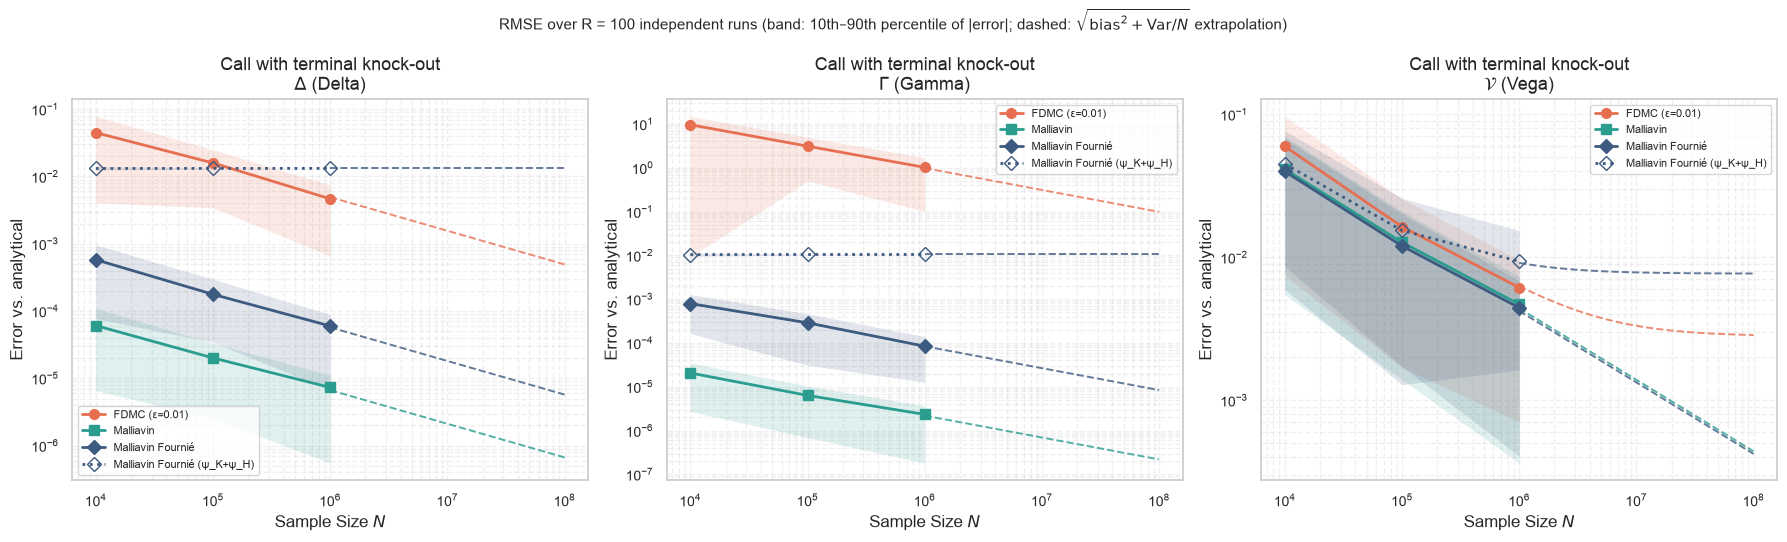

In [17]:
import Utilities as utils

rep_summary = pd.read_csv("./results/replications_summary.csv")
ko = rep_summary[
    (rep_summary["Product"] == "Call with terminal knock-out")
    & (rep_summary["N"] == rep_summary["N"].max())
    & rep_summary["Method"].str.startswith("Malliavin")
].copy()
ko["bias / bias_se"] = ko["bias"] / ko["bias_se"]
std_var = ko[ko["Method"] == "Malliavin"].set_index("Greek")["var_per_path"]
ko["var vs standard"] = ko["var_per_path"].to_numpy() / std_var.loc[ko["Greek"]].to_numpy()
display(ko[["Greek", "Estimator", "benchmark", "mean", "bias", "bias / bias_se", "sd", "var_per_path", "var vs standard", "coverage_95"]]
        .sort_values(["Greek", "Estimator"]).reset_index(drop=True))

fig = utils.plot_replication_error_vs_N(rep_summary, "Call with terminal knock-out")
plt.show()


### 6.2 The Bias of $\psi_K + \psi_H$ Depends on the Cutoff Family

One run of $N = 2 \times 10^6$ paths per cutoff and combination, with the same paths throughout. Compact cutoffs give identical results for both combinations; non-compact ones (Gaussian, Cauchy) are biased with the sum.

In [18]:
bench_b = greeks_european_barrier_up_and_out_call(p_bar)
paths_ko = generate_paths(T_b, 2_000_000, seed=7)
rows = []
for ctype in ["gaussian", "cauchy", "cubic", "cosine", "quintic"]:
    for comb in ["union", "sum"]:
        res = malliavin_fournier_greeks_european_barrier_up_and_out_call(
            p_bar, paths=paths_ko, cutoff_type=ctype, bandwidth=delta_b,
            cutoff_combination=comb, return_stats=True,
        )
        for g in ("delta", "gamma", "vega"):
            rows.append({
                "cutoff": ctype, "combination": comb, "Greek": g,
                "estimate": res[g], "benchmark": bench_b[g],
                "error / SE": (res[g] - bench_b[g]) / res[f"{g}_se"],
            })
df_comb = pd.DataFrame(rows)
display(df_comb.pivot_table(index=["cutoff", "combination"], columns="Greek", values="error / SE").round(1))


Greek                 delta  gamma  vega
cutoff   combination                    
cauchy   sum         -279.5   52.7  -2.6
         union          2.3   -0.5   0.5
cosine   sum            2.3   -0.6  -0.7
         union          2.3   -0.6  -0.7
cubic    sum            2.3   -0.5  -0.7
         union          2.3   -0.5  -0.7
gaussian sum         -303.9  206.1  -1.0
         union          2.3   -0.5   0.7
quintic  sum            2.3   -0.6  -0.8
         union          2.3   -0.6  -0.8

### 6.3 Per-Path Variance vs. Bandwidth (Unbiased Combination)

Even with the unbiased cutoff, localization does not reduce the variance of Delta or Gamma here, for any $\delta \le (H-K)/2$:
1. About $90\%$ of paths end outside $[100, 105.25]$, where the payoff, and so the standard Malliavin sample, is zero. Inside, the payoff is at most $5.25$ and the weight is small.
2. Localization replaces part of that small weighted payoff by $\Phi\psi'$ and $\Phi\psi''$ terms of order $1/\delta$ and $1/\delta^2$, with $\delta$ capped at $2.625$ by the corridor.

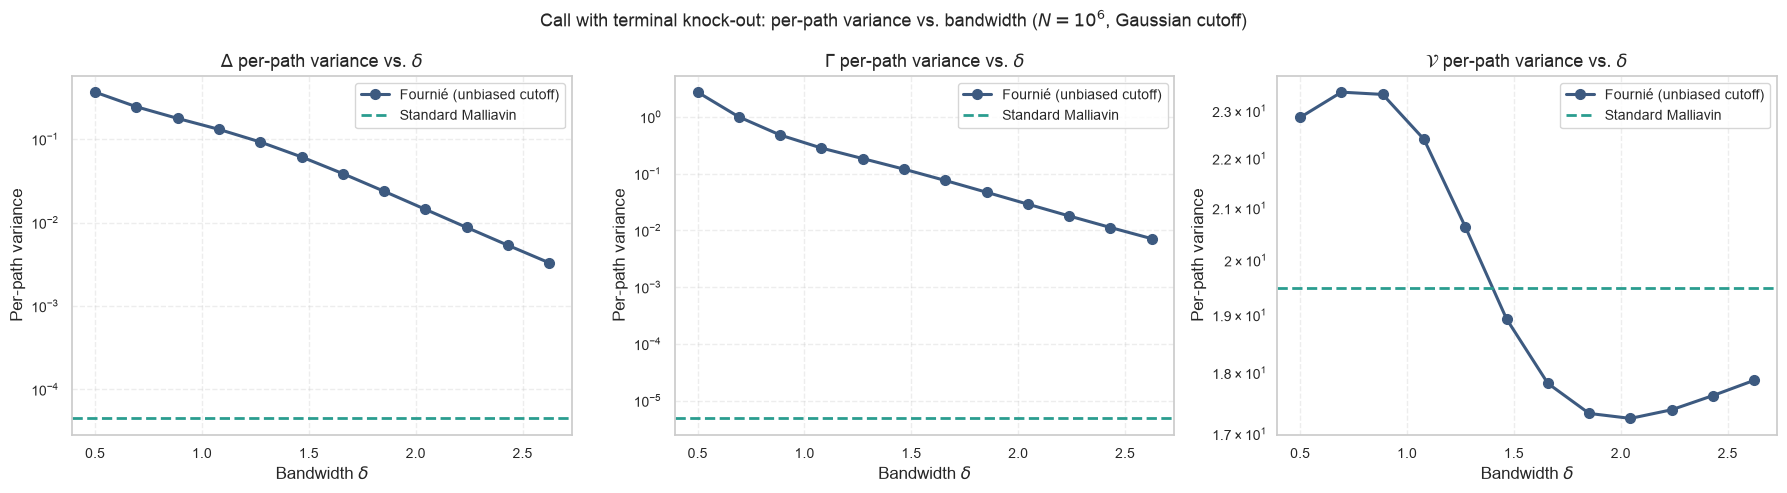

In [19]:
paths_var = generate_paths(T_b, 1_000_000, seed=11)
std_samples = malliavin_samples_european(payoffs.call_terminal_knockout, p_bar, paths_var)
deltas_sweep_b = np.linspace(0.5, delta_b, 12)
var_rows = []
for d in deltas_sweep_b:
    four = malliavin_fournier_samples_european_call_terminal_knockout(p_bar, paths_var, bandwidth=float(d))
    var_rows.append({g: np.var(four[g], ddof=1) for g in ("delta", "gamma", "vega")} | {"delta_bw": d})
df_var_b = pd.DataFrame(var_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, g, label in zip(axes, ("delta", "gamma", "vega"), (r"$\Delta$", r"$\Gamma$", r"$\mathcal{V}$")):
    ax.plot(df_var_b["delta_bw"], df_var_b[g], marker="o", color="#3d5a80", linewidth=2.2, label="Fournié (unbiased cutoff)")
    ax.axhline(np.var(std_samples[g], ddof=1), color="#2a9d8f", linestyle="--", linewidth=2, label="Standard Malliavin")
    ax.set_yscale("log")
    ax.set_xlabel(r"Bandwidth $\delta$")
    ax.set_ylabel("Per-path variance")
    ax.set_title(f"{label} per-path variance vs. $\\delta$")
    ax.legend(frameon=True)
plt.suptitle("Call with terminal knock-out: per-path variance vs. bandwidth ($N = 10^6$, Gaussian cutoff)", fontsize=13)
plt.tight_layout()
plt.show()


---
## 7. Summary

### 1-month call
- The standard Malliavin weights grow as $T$ shrinks, and the call payoff is unbounded, so the standard estimator has a large per-path variance at $T = 1/12$.
- Fournié localization replaces the weight by the pathwise derivative away from the strike. Sections 3 and 4 measure the variance reduction for each Greek; Gamma uses the general localized formula $\Phi\psi\pi^\Gamma + (\Phi''(1-\psi) - 2\Phi'\psi' - \Phi\psi'')(S_T/S_0)^2$.
- The best bandwidth depends on the Greek (Section 4): narrower for Delta and Vega, whose boundary term is damped by $(S_T - K)$, wider for Gamma, whose term $-2\,\mathbf{1}_{S_T > K}\psi'$ is not.

### Call with terminal knock-out
- With one cutoff covering $K$ and $H$, the localized estimator is unbiased only if $\psi = 1$ and $\psi' = 0$ at both points. $\psi = 1 - (1-\psi_K)(1-\psi_H)$ satisfies this for every cutoff family. $\psi_K + \psi_H$ satisfies it only when the bumps do not overlap (compact cutoffs); with the Gaussian it is badly biased (Section 6.1–6.2).
- Even unbiased, Fournié has a much larger per-path variance than standard Malliavin for Delta and Gamma, and a similar one for Vega (Section 6.1, 6.3). For a narrow knock-out interval, use standard Malliavin.